# Fraud-Risk Intelligence Pipeline: calibrated probabilities, cost-optimal decisions, explanations

Each transaction receives a calibrated fraud probability, an operational decision (Approve / Review / Block) and an explanation for high-risk cases.


In [1]:
import joblib
import pandas as pd
import numpy as np
from fraud_engine.config import SEED, OUT, FIG, SUPP, SCENARIOS, BASE, TARGET
from fraud_engine import data_quality as dq
from fraud_engine import config, models, features, eda, calibration as cal, costs, explain, robustness, engine
from IPython.display import Image, display
from sklearn.calibration import CalibratedClassifierCV
from sklearn.base import clone
import sys
import time
import json
import warnings
sys.path.insert(0, "src")
warnings.filterwarnings("ignore")

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)
pd.set_option("display.float_format", "{:.4f}".format)
np.random.seed(SEED)

# results store -> outputs/supplementary/results.joblib (used by the report builders)
R = {}
CACHE = OUT / "cache"
CACHE.mkdir(exist_ok=True)
# set False (or delete outputs/cache) to recompute the slow searches from scratch
USE_CACHE = True

def cached(name, fn):
    f = CACHE / f"{name}.joblib"
    if USE_CACHE and f.exists():
        return joblib.load(f)
    out = fn()
    joblib.dump(out, f)
    return out

def show(path): display(Image(filename=str(path)))

df = pd.read_csv(config.DATA_PATH)
dev, test = models.split_data(df)
Xd, yd = models.xy(dev)
Xt, yt = models.xy(test)
# amount used for cost maths when amount is missing
AMT_FILL = float(Xd.transaction_amount.median())
amt_d = Xd.transaction_amount.fillna(AMT_FILL).values
amt_t = Xt.transaction_amount.fillna(AMT_FILL).values
print(f"all={df.shape}  dev={dev.shape} (fraud {yd.mean():.3%})  test={test.shape} (fraud {yt.mean():.3%})")
R["split"] = {"n_dev": len(dev), "n_test": len(
    test), "fraud_dev": int(yd.sum()), "fraud_test": int(yt.sum())}

all=(3000, 25)  dev=(2400, 25) (fraud 12.125%)  test=(600, 25) (fraud 12.167%)


## Data forensics and quality engineering

The audit runs on the full table (no labels are used for any modelling decision here; fraud rates are used only to _describe_ missingness).


In [2]:
schema = dq.schema_table(df)
display(schema)

R["dup"] = dq.duplicates(df)
print(R["dup"])

imp = dq.impossible_values(df)
display(imp)

R["impossible"] = imp
out_tab = dq.outlier_table(df)
display(out_tab)

R["outliers"] = out_tab

,column,dtype,n_unique,missing_n,missing_pct,min,median,max,skew,top_value
0,transaction_id,str,3000,0,0.0000,NaN,NaN,NaN,NaN,TXN5000001
1,hour,int64,24,0,0.0000,0.0000,12.0000,23.0000,-0.0300,NaN
2,day_of_week,int64,7,0,0.0000,0.0000,3.0000,6.0000,0.0500,NaN
3,transaction_amount,float64,2779,53,1.7700,4.1200,88.3900,5538.1516,15.4500,NaN
4,distance_from_usual_location_km,float64,2402,75,2.5000,0.4900,29.9700,1173.2691,14.6200,NaN
5,transactions_last_1h,int64,11,0,0.0000,0.0000,2.0000,10.0000,0.7300,NaN
6,transactions_last_24h,int64,25,0,0.0000,0.0000,7.0000,113.0000,13.1800,NaN
7,account_age_days,int64,1464,0,0.0000,1.0000,887.0000,1799.0000,0.0100,NaN
8,failed_logins_24h,int64,4,0,0.0000,0.0000,0.0000,3.0000,1.6600,NaN
9,prior_chargebacks,int64,4,0,0.0000,0.0000,0.0000,3.0000,2.8000,NaN


{'full_row_duplicates': 0, 'duplicate_ids': 0, 'duplicates_ignoring_id': 0}


,count
hour outside 0-23,0
day_of_week outside 0-6,0
non-positive amount,0
negative distance,0
transactions_last_1h > transactions_last_24h,0
"risk score outside [0,1]",0
account_age_days <= 0,0
ATM channel with card not present (logical inconsistency),121
device older than account (possible device re-use),1240
login_to_transaction_minutes at 120 (possible cap / censoring),6


,column,p99,max,extreme_threshold_3IQR,n_extreme,fraud_rate_extreme,fraud_rate_other
0,transaction_amount,679.1856,5538.1516,473.3500,63,0.2857,0.1182
1,distance_from_usual_location_km,125.6740,1173.2691,143.3700,18,0.3889,0.1214
2,transactions_last_24h,15.0000,113.0000,18.0000,6,0.0000,0.1216
3,transactions_last_1h,6.0000,10.0000,9.0000,1,1.0000,0.1210
4,login_to_transaction_minutes,82.7239,120.0000,66.1100,59,0.0678,0.1225
5,account_age_days,1778.0100,1799.0000,4079.7500,0,NaN,0.1213


In [3]:
miss = dq.missingness_signal(df)
display(miss)

R["missingness"] = miss
print("Dev-set check, does the missing flag add information beyond the observed features? (see ablation in section C)")

,column,n_missing,pct_missing,fraud_rate_missing,fraud_rate_observed,fisher_p_value,auc_predicting_missingness
0,transaction_amount,53,1.7700,0.0943,0.1218,0.6740,0.4946
1,distance_from_usual_location_km,75,2.5000,0.0533,0.1231,0.0727,0.5396
2,merchant_risk_score,60,2.0000,0.0333,0.1231,0.0281,0.4558
3,ip_risk_score,45,1.5000,0.1111,0.1215,1.0000,0.4825
4,login_to_transaction_minutes,60,2.0000,0.1167,0.1214,1.0000,0.5447
5,authentication_level,289,9.6300,0.1903,0.1140,0.0004,0.5012


Dev-set check, does the missing flag add information beyond the observed features? (see ablation in section C)


In [4]:
display(dq.TREATMENT_LOG)
display(dq.LEAKAGE_REGISTER)

dq.TREATMENT_LOG.to_csv(SUPP / "data_quality_treatments.csv", index=False)
dq.LEAKAGE_REGISTER.to_csv(SUPP / "leakage_register.csv", index=False)

schema.to_csv(SUPP / "data_quality_schema.csv", index=False)
miss.to_csv(SUPP / "data_quality_missingness.csv", index=False)
imp.to_csv(SUPP / "data_quality_impossible_values.csv")
out_tab.to_csv(SUPP / "data_quality_outliers.csv", index=False)

R["treatments"] = dq.TREATMENT_LOG
R["leakage"] = dq.LEAKAGE_REGISTER

,issue,scale,treatment,rationale
0,"Missing numeric values (amount, distance, merc...",1.5-2.5% each,Median imputation inside the pipeline (fit on ...,No signal after Bonferroni correction (6 tests...
1,Missing authentication_level,9.6%,Kept as its own category 'Missing'.,Fraud rate is 19.0% vs 11.4% when observed (Fi...
2,"Heavy right tails (amount, distance, 24h veloc...","max amount 5,538 vs median 88",No rows removed or capped. Log transforms and ...,Instructions forbid removing difficult observa...
3,ATM + card not present,121 rows,Kept; flagged with atm_cnp_inconsistent.,Logical inconsistency in source data; report t...
4,login_to_transaction_minutes = 120,6 rows,Kept (possible cap at 120).,Immaterial.
5,Duplicates,0,None needed.,"Checked full rows, ids, and rows ignoring id."
6,transaction_id,unique,Dropped from the model; retained in the proces...,Leakage / no generalisable signal.
7,Categorical variables,2-10 levels,One-hot encoding (unknown levels ignored).,Low cardinality: no target encoding needed.


,field,leakage risk,decision
0,transaction_id,Identifier (sequential). Could encode time/ord...,NOT permitted as a feature. Dropped.
1,transactions_last_1h / _24h,Velocity counters. Leak if the window includes...,Permitted if computed strictly before the tran...
2,prior_chargebacks,Chargebacks are reported weeks after the fraud...,Permitted only as a point-in-time count (charg...
3,merchant_risk_score / ip_risk_score,If merchant score is refreshed using confirmed...,Permitted if the score is versioned and as-of ...
4,authentication_level,May be the outcome of a risk-based step-up tri...,Permitted only if the field is known before th...
5,login_to_transaction_minutes,Known at scoring time (session telemetry).,Permitted.
6,failed_logins_24h,Known at scoring time if the window ends at th...,Permitted.
7,account_age_days / device_age_days / email_age...,Known at scoring time. Must be computed relati...,Permitted (verify reference date).
8,hour / day_of_week,Known at scoring time. No full timestamp exist...,Permitted. Temporal leakage cannot be tested; ...
9,fraud (target),Label is confirmed later (chargeback / investi...,Target only. Labels arrive with delay: monitor...


## Advanced exploratory analysis
Fraud rates use 95% Wilson intervals (orange dashed line = overall 12.1%). Quantile bins are used for nonlinear effects. Intervals are wide because there are only 364 fraud cases, so only large gaps should be trusted.

12 figure files, incl. 4 interaction heat-maps (fig08-fig11)


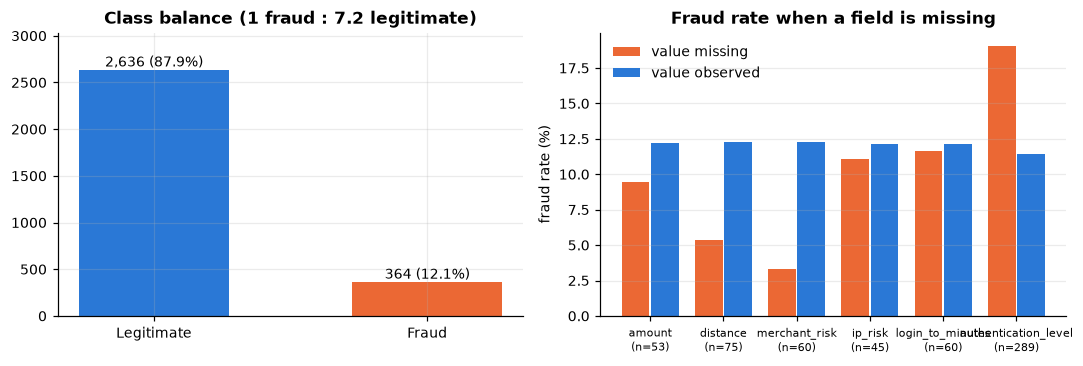

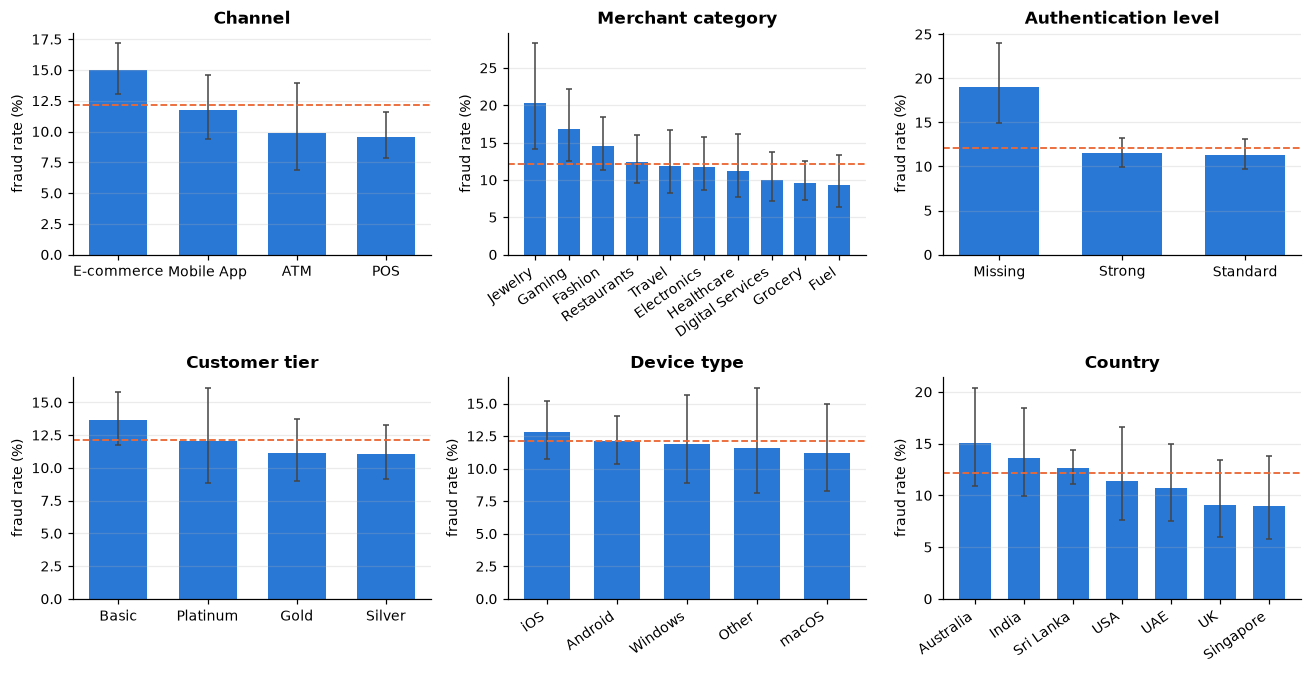

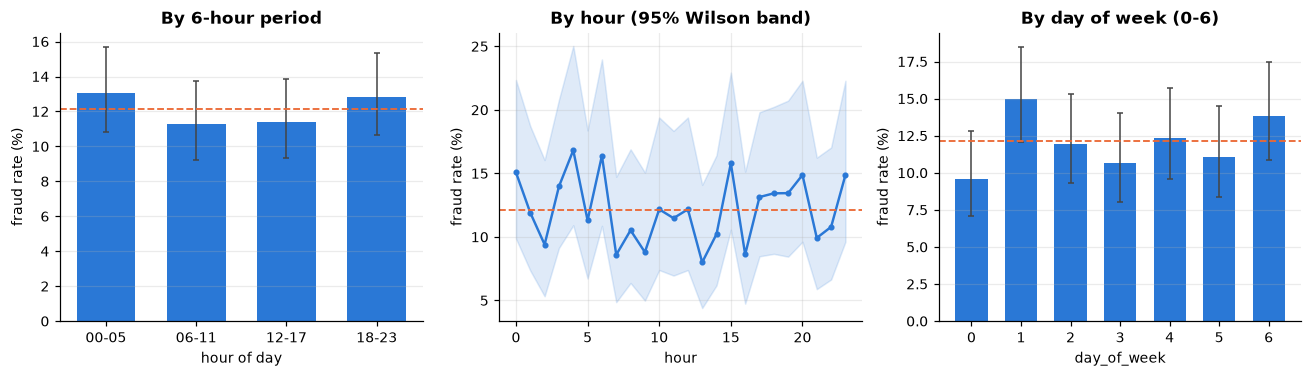

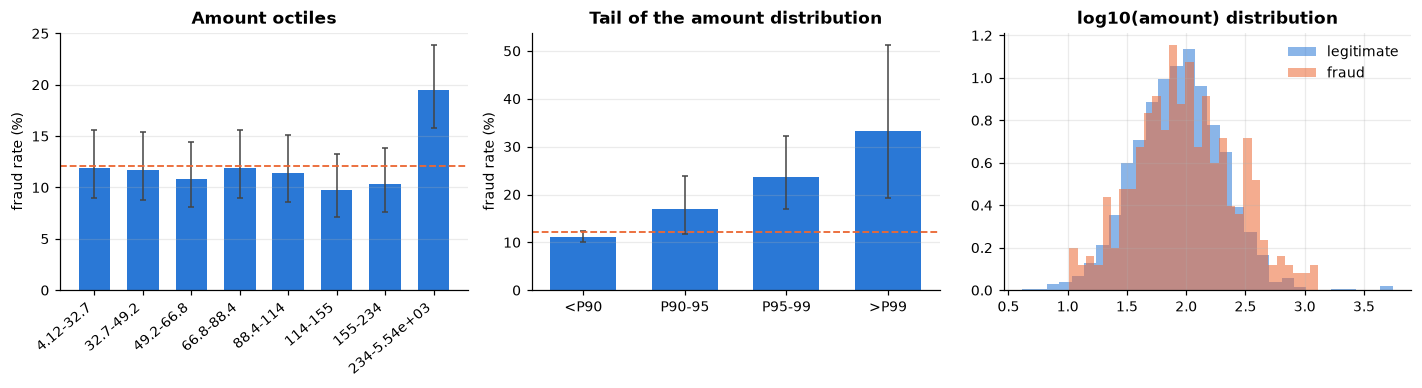

In [5]:
paths = eda.run_all(df)
print(len(paths), "figure files,", "incl. 4 interaction heat-maps (fig08-fig11)")

for p in paths[:4]:
    show(p)

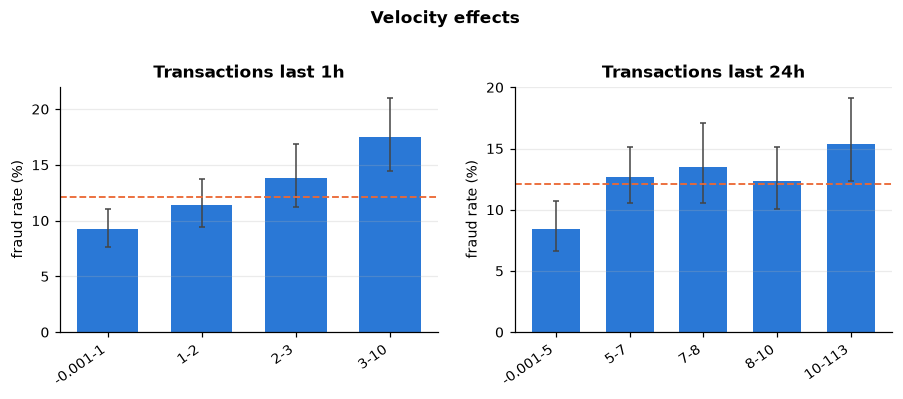

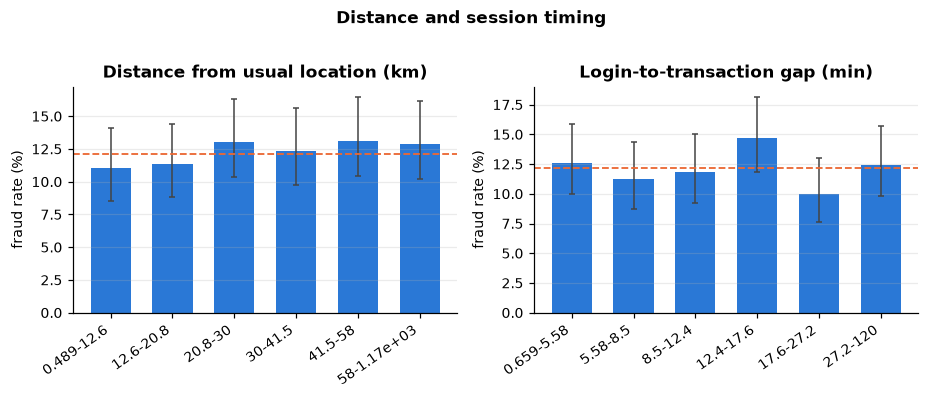

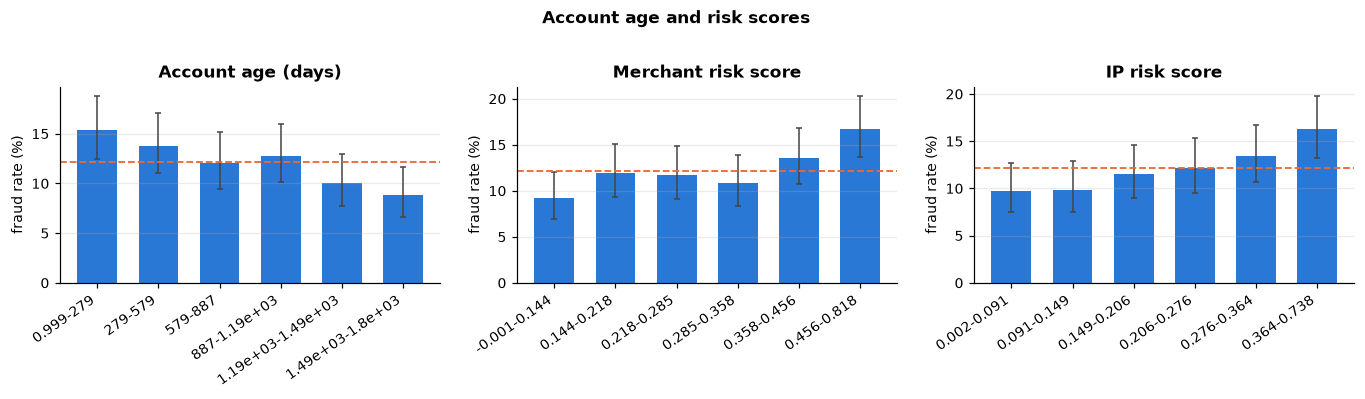

In [6]:
for p in paths[4:7]: show(p)

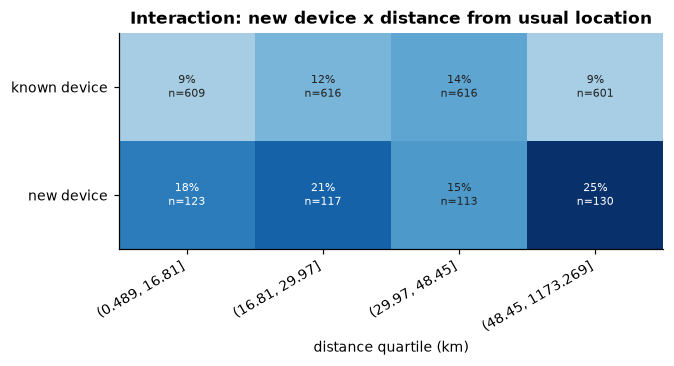

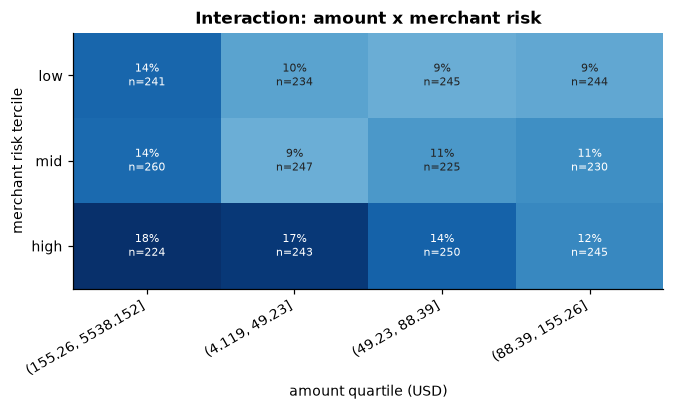

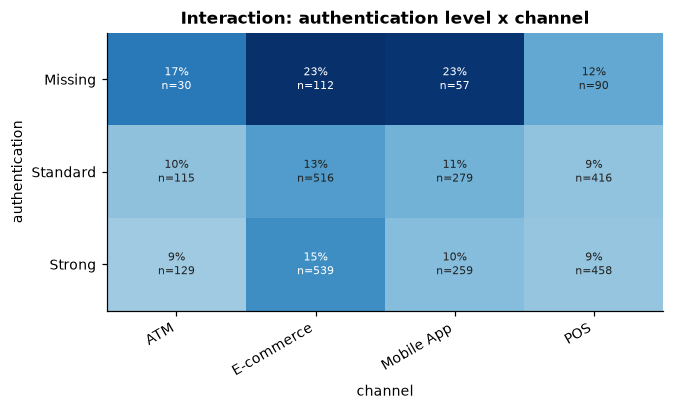

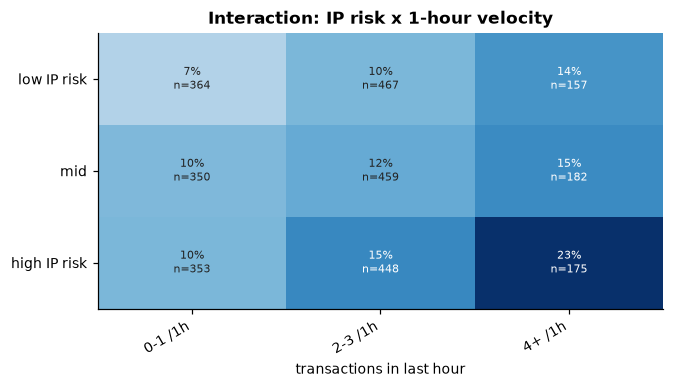

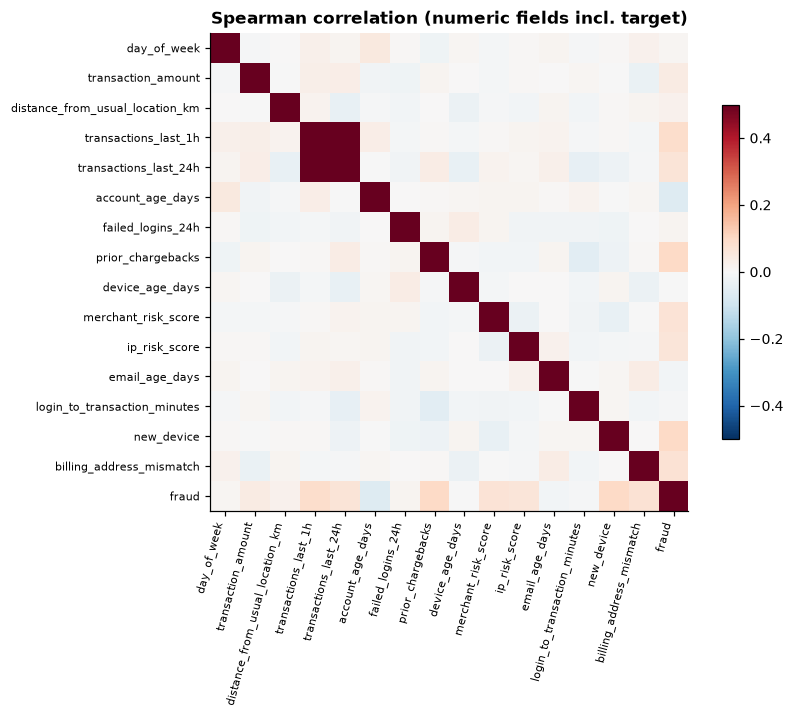

In [7]:
for p in paths[7:]: show(p)

In [8]:
# Quantified interaction check: joint fraud rate vs what the two marginal lifts would imply (multiplicative expectation)
fe0 = features.FeatureEngineer().fit(Xd)
Zd0 = fe0.transform(Xd)
Zd0["y"] = yd


def lift_pair(a, b, label):
    base = Zd0.y.mean()
    ra, rb = Zd0.loc[a, "y"].mean() / base, Zd0.loc[b, "y"].mean() / base
    both = a & b
    return {"pair": label, "n_both": int(both.sum()), "fraud_rate_both": Zd0.loc[both, "y"].mean(),
            "lift_a": ra, "lift_b": rb, "expected_lift_if_independent": ra * rb, "observed_lift": Zd0.loc[both, "y"].mean() / base}


hi_m = Zd0.merchant_risk_score >= Zd0.merchant_risk_score.quantile(.75)
hi_ip = Zd0.ip_risk_score >= Zd0.ip_risk_score.quantile(.75)
big = Zd0.amount_extreme_flag == 1
rows = [lift_pair(Zd0.new_device == 1, Zd0.far_from_home_flag == 1, "new device x far from home (>P90)"),
        lift_pair(Zd0.new_device == 1, Zd0.distance_from_usual_location_km >=
                  Zd0.distance_from_usual_location_km.quantile(.75), "new device x distance top quartile"),
        lift_pair(Zd0.log_amount_to_category_median >= np.log1p(1.5),
                  hi_m, "amount 1.5x category median x high merchant risk"),
        lift_pair(Zd0.authentication_level == "Missing", Zd0.channel ==
                  "E-commerce", "auth missing x E-commerce"),
        lift_pair(hi_ip, Zd0.transactions_last_1h >=
                  3, "high IP risk x 3+ txns in 1h"),
        lift_pair(Zd0.billing_address_mismatch == 1, Zd0.new_device == 1, "billing mismatch x new device")]
inter = pd.DataFrame(rows)
display(inter)
R["interaction_lift"] = inter

,pair,n_both,fraud_rate_both,lift_a,lift_b,expected_lift_if_independent,observed_lift
0,new device x far from home (>P90),43,0.2558,1.6245,1.1231,1.8244,2.1098
1,new device x distance top quartile,103,0.2330,1.6245,0.9148,1.4861,1.9217
2,amount 1.5x category median x high merchant risk,172,0.1977,1.1585,1.4817,1.7167,1.6303
3,auth missing x E-commerce,88,0.2386,1.7287,1.1782,2.0368,1.9681
4,high IP risk x 3+ txns in 1h,231,0.1905,1.2774,1.3081,1.6709,1.5709
5,billing mismatch x new device,37,0.3243,1.4638,1.6245,2.3780,2.6748


## Feature engineering
32 engineered features (`features.py`). Everything that learns from data (group medians, quantile cut-offs, z-score statistics) is fitted on training folds only. The table lists what each feature is and whether it is available at prediction time.

In [9]:
fd = pd.DataFrame([{"feature": k, "definition": v[0], "available at prediction time?": v[1]}
                  for k, v in features.FEATURE_DOCS.items()])
display(fd)

fd.to_csv(SUPP / "feature_dictionary.csv", index=False)
R["feature_docs"] = fd

,feature,definition,available at prediction time?
0,velocity_ratio_1h_24h,transactions_last_1h / (transactions_last_24h ...,Available if the velocity counters exclude the...
1,burst_flag,1 if 4+ transactions in the last hour.,Same as above.
2,amount_log,log1p(transaction_amount): tames the heavy rig...,Available.
3,log_amount_to_category_median,log1p(amount / training median amount of the m...,Available; medians fitted on training data only.
4,amount_z_tier,z-score of log-amount within customer tier (tr...,Available; statistics fitted on training data ...
5,amount_extreme_flag,1 if amount above the training 95th percentile.,Available; cut-off fitted on training data only.
6,risk_product,merchant_risk_score * ip_risk_score: both risk...,Available if both scores are computed as-of th...
7,risk_max,"max(merchant_risk_score, ip_risk_score).",Same.
8,risk_mean,mean of merchant and IP risk scores.,Same.
9,amount_x_merchant_risk,amount_log * merchant_risk_score: large purcha...,Available.


In [10]:
# Ablation with reproducible repeated CV (5 folds x 3 repeats) on the development set, default hyper-parameters
def ablate():
    rows = []
    variants = {"raw features (authentication gap kept as category)": dict(engineer=False, missing_indicators=False),
                "raw + numeric missing flags": dict(engineer=False, missing_indicators=True),
                "raw + engineered (final choice)": dict(engineer=True, missing_indicators=False),
                "raw + engineered + numeric missing flags": dict(engineer=True, missing_indicators=True)}
    for m in ["logreg", "rf", "lgbm"]:
        params = {"class_weight": "balanced"} if m != "rf" else {
            "class_weight": "balanced_subsample", "min_samples_leaf": 5, "max_depth": 8}
        if m == "lgbm":
            params.update(n_estimators=150, learning_rate=0.05,
                          num_leaves=15, min_child_samples=20)
        for v, kw in variants.items():
            s = models.cv_scores(models.build_pipeline(
                m, model_params=params, **kw), Xd, yd)
            rows.append({"model": models.MODEL_LABELS[m], "features": v, "roc_auc": s.roc_auc.mean(), "roc_auc_sd": s.roc_auc.std(),
                         "pr_auc": s.pr_auc.mean(), "pr_auc_sd": s.pr_auc.std()})
    return pd.DataFrame(rows)


abl = cached("ablation", ablate)
display(abl)

R["ablation"] = abl
abl.to_csv(SUPP / "ablation_feature_sets.csv", index=False)

,model,features,roc_auc,roc_auc_sd,pr_auc,pr_auc_sd
0,Logistic Regression,raw features (authentication gap kept as categ...,0.6682,0.0399,0.2466,0.0410
1,Logistic Regression,raw + numeric missing flags,0.6664,0.0417,0.2463,0.0401
2,Logistic Regression,raw + engineered (final choice),0.6686,0.0424,0.2458,0.0394
3,Logistic Regression,raw + engineered + numeric missing flags,0.6620,0.0456,0.2403,0.0384
4,Random Forest,raw features (authentication gap kept as categ...,0.6333,0.0310,0.1981,0.0247
5,Random Forest,raw + numeric missing flags,0.6361,0.0354,0.2029,0.0326
6,Random Forest,raw + engineered (final choice),0.6328,0.0426,0.2025,0.0309
7,Random Forest,raw + engineered + numeric missing flags,0.6365,0.0405,0.2051,0.0321
8,LightGBM,raw features (authentication gap kept as categ...,0.6128,0.0285,0.1905,0.0220
9,LightGBM,raw + numeric missing flags,0.6129,0.0293,0.1906,0.0219


## Baseline and advanced models, hyper-parameter optimisation
Logistic Regression (transparent baseline) plus Random Forest, HistGradientBoosting and LightGBM. Each is tuned with `RandomizedSearchCV` (30 candidates x 5 stratified folds, seed 42) on **average precision (PR-AUC)** over the development set only. `class_weight` is part of the search space; resampling is compared separately in section G.

In [11]:
def run_tuning():
    out = {}
    for n in ["logreg", "rf", "hgb", "lgbm"]:
        t = time.time()
        s = models.tune(n, Xd, yd, n_iter=30)
        out[n] = {"params": s.best_params_, "cv_pr_auc": s.best_score_, "estimator": s.best_estimator_,
                  "search": pd.DataFrame(s.cv_results_)[["mean_test_score", "std_test_score", "rank_test_score"]].assign(model=n), "secs": time.time() - t}
        print(n, round(out[n]["cv_pr_auc"], 4), f"{out[n]['secs']:.0f}s")
    return out


tuned = cached("tuned", run_tuning)
display(pd.DataFrame({models.MODEL_LABELS[n]: {"best params": {k.replace("model__", ""): (round(v, 4) if isinstance(
    v, float) else v) for k, v in t["params"].items()}, "search CV PR-AUC": round(t["cv_pr_auc"], 4)} for n, t in tuned.items()}).T)
R["tuned_params"] = {n: t["params"] for n, t in tuned.items()}

logreg 0.2565 12s
rf 0.2274 172s
hgb 0.2444 101s
lgbm 0.244 27s


,best params,search CV PR-AUC
Logistic Regression,"{'C': 0.1445, 'class_weight': None}",0.2565
Random Forest,"{'n_estimators': 200, 'min_samples_leaf': 3, '...",0.2274
HistGradientBoosting,"{'class_weight': None, 'l2_regularization': 0....",0.2444
LightGBM,"{'class_weight': None, 'colsample_bytree': 0.6...",0.2440


In [12]:
# Untuned logistic baseline and all tuned models: 5x3 repeated CV, per-fold metrics (not used for selection, for variability)
def fold_table():
    res = {"Logistic Regression (untuned baseline)": models.cv_scores(
        models.build_pipeline("logreg"), Xd, yd)}
    for n, t in tuned.items():
        res[models.MODEL_LABELS[n] +
            " (tuned)"] = models.cv_scores(clone(t["estimator"]), Xd, yd)
    return res


folds = cached("folds", fold_table)
cvtab = pd.concat({k: models.summarize(v) .stack()
                  for k, v in folds.items()}, axis=1).T
cvtab.columns = [f"{a}_{b}" for a, b in cvtab.columns]
display(cvtab[[c for c in cvtab.columns if c.split(
    "_")[-1] in ("mean", "std")]].round(4))
R["cv_table"] = cvtab
R["folds"] = folds
pd.concat({k: v for k, v in folds.items()}, names=["model"]).reset_index(
    level=0).to_csv(SUPP / "cv_fold_metrics.csv", index=False)

,roc_auc_mean,roc_auc_std,pr_auc_mean,pr_auc_std,brier_mean,brier_std,recall_mean,recall_std,precision_mean,precision_std,f1_mean,f1_std
Logistic Regression (untuned baseline),0.6707,0.0453,0.2493,0.0432,0.1046,0.0066,0.0561,0.0221,0.4107,0.1797,0.0966,0.0338
Logistic Regression (tuned),0.6755,0.0457,0.2540,0.0452,0.1033,0.0061,0.0458,0.0222,0.4800,0.2647,0.0814,0.0366
Random Forest (tuned),0.6593,0.0497,0.2230,0.0359,0.1032,0.0026,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
HistGradientBoosting (tuned),0.6219,0.0394,0.2081,0.0418,0.1090,0.0051,0.0435,0.0315,0.3194,0.1834,0.0755,0.0528
LightGBM (tuned),0.6630,0.0417,0.2395,0.0392,0.1024,0.0024,0.0034,0.0071,0.1667,0.3619,0.0067,0.0140


## Imbalanced learning
Fraud prevalence is 12.1% (about 1 fraud per 7.2 legitimate), so a classifier that never flags anything scores 87.9% accuracy. We therefore rank by PR-AUC (random baseline = prevalence), recall, precision, F1 and business cost. Four strategies are compared for the logistic baseline and the best nonlinear model: nothing, class weighting, SMOTE and random under-sampling (50% minority share). SMOTE and under-sampling are `imblearn` pipeline steps: they run **only on the training part of each fold**, never on validation or test rows.

In [13]:
best_tree = max(["rf", "hgb", "lgbm"], key=lambda n: tuned[n]["cv_pr_auc"])
print("best nonlinear model by CV PR-AUC:", best_tree)

def imbalance_study():
    rows = []
    for n in ["logreg", best_tree]:
        base = {k.replace("model__", ""): v for k, v in tuned[n]["params"].items(
        ) if k != "model__class_weight"}
        for strat in ["none", "class_weight", "smote", "undersample"]:
            params = dict(base)
            if strat == "class_weight":
                params["class_weight"] = "balanced_subsample" if n == "rf" else "balanced"
            pipe = models.build_pipeline(n, sampler=strat if strat in (
                "smote", "undersample") else None, model_params=params)
            s = models.cv_scores(pipe, Xd, yd, repeated=False)
            p = models.oof_proba(pipe, Xd, yd)
            thr, c, _, _ = costs.optimize_binary(p, yd, amt_d, BASE)
            rows.append({"model": models.MODEL_LABELS[n], "strategy": strat, "pr_auc": s.pr_auc.mean(), "roc_auc": s.roc_auc.mean(),
                         "recall@0.5": s.recall.mean(), "precision@0.5": s.precision.mean(), "f1@0.5": s.f1.mean(), "brier": s.brier.mean(),
                         "mean_pred": p.mean(), "best_threshold": thr, "min_cost_per_1000": c / len(yd) * 1000})
    return pd.DataFrame(rows)

imb = cached("imbalance", imbalance_study)
display(imb)

R["imbalance"] = imb
R["prevalence"] = float(yd.mean())

best nonlinear model by CV PR-AUC: hgb


,model,strategy,pr_auc,roc_auc,recall@0.5,precision@0.5,f1@0.5,brier,mean_pred,best_threshold,min_cost_per_1000
0,Logistic Regression,none,0.2565,0.6767,0.0480,0.4390,0.0850,0.1035,0.1232,0.3250,17351.9917
1,Logistic Regression,class_weight,0.2504,0.6736,0.5499,0.1955,0.2880,0.2138,0.4263,0.8091,17307.5833
2,Logistic Regression,smote,0.2301,0.6564,0.5499,0.1917,0.2841,0.2187,0.4223,0.8150,18737.8375
3,Logistic Regression,undersample,0.2334,0.6597,0.3646,0.2510,0.2931,0.1566,0.3154,0.7018,18199.2458
4,HistGradientBoosting,none,0.2444,0.6368,0.0617,0.4619,0.1080,0.1051,0.0991,0.3200,18008.6083
5,HistGradientBoosting,class_weight,0.2192,0.6315,0.2403,0.2048,0.2208,0.1442,0.2590,0.6800,18637.0833
6,HistGradientBoosting,smote,0.2293,0.6402,0.0650,0.3860,0.1105,0.1058,0.1176,0.3432,17768.1125
7,HistGradientBoosting,undersample,0.2072,0.6242,0.2953,0.1962,0.2355,0.1628,0.2847,0.7564,19192.9333


## Probability calibration
For each tuned model we compare uncalibrated scores with **Platt scaling (sigmoid)** and **isotonic regression**. Calibration is evaluated on **out-of-fold** predictions: in every outer fold the calibrator is fitted by inner 3-fold CV on the training part only, so the scored rows never influenced the calibrator. Metrics: Brier score, log-loss, expected calibration error (ECE, equal-frequency bins), and the calibration slope/intercept (ideal 1 / 0).

In [14]:
def calib_all():
    out = {}
    for n, t in tuned.items():
        tab, probs = cal.compare_methods(clone(t["estimator"]), Xd, yd)
        out[n] = {"table": tab, "probs": probs}
    return out

CAL = cached("calibration", calib_all)
ctab = pd.concat({models.MODEL_LABELS[n]: v["table"]
                 for n, v in CAL.items()}, names=["model", "method"])
display(ctab.round(4))
R["calibration"] = ctab
ctab.to_csv(SUPP / "calibration_comparison.csv")
# production calibrator per model: sigmoid unless isotonic is clearly better (see rule below)
# Rule: prefer the smoother parametric Platt scaling unless isotonic improves Brier by >2% (only ~290 fraud cases: isotonic can overfit)
BEST_CAL = {n: ("isotonic" if v["table"].loc["isotonic", "brier"] < 0.98 *
                v["table"].loc["sigmoid", "brier"] else "sigmoid") for n, v in CAL.items()}
P_CAL = {n: CAL[n]["probs"][BEST_CAL[n]] for n in CAL}
print(BEST_CAL)
R["best_cal"] = BEST_CAL

brier  log_loss    ece  cal_slope  cal_intercept  mean_pred  observed_rate
model                method                                                                              
Logistic Regression  none     0.1035    0.3603 0.0294     0.5714        -0.8022     0.1232         0.1212
                     sigmoid  0.1029    0.3520 0.0168     0.9871        -0.0327     0.1221         0.1212
                     isotonic 0.1022    0.3547 0.0128     0.7578        -0.4563     0.1223         0.1212
Random Forest        none     0.1029    0.3536 0.0125     1.0689         0.1398     0.1203         0.1212
                     sigmoid  0.1033    0.3554 0.0159     1.1402         0.2652     0.1215         0.1212
                     isotonic 0.1030    0.3538 0.0137     0.8690        -0.2483     0.1217         0.1212
HistGradientBoosting none     0.1051    0.3758 0.0473     0.4595        -0.8502     0.0991         0.1212
                     sigmoid  0.1040    0.3579 0.0209     1.7615         1.4612     0.1216         0.1212
                     isotonic 0.1041    0.3581 0.0185     1.1177         0.2185     0.1219         0.1212
LightGBM             none     0.1020    0.3507 0.0091     1.0325         0.0866     0.1187         0.1212
                     sigmoid  0.1021    0.3510 0.0174     1.2796         0.5165     0.1221         0.1212
                     isotonic 0.1023    0.3517 0.0158     0.9694        -0.0718     0.1228         0.1212

{'logreg': 'sigmoid', 'rf': 'sigmoid', 'hgb': 'sigmoid', 'lgbm': 'sigmoid'}


In [15]:
import matplotlib.pyplot as plt

fig, axs = plt.subplots(1, 4, figsize=(16, 3.8), sharey=True)
for ax, (n, v) in zip(axs, CAL.items()):
    for m, c in [("none", "#8a8984"), ("sigmoid", "#2a78d6"), ("isotonic", "#eb6834")]:
        x, y_ = cal.reliability_points(yd, v["probs"][m])
        ax.plot(x, y_, marker="o", ms=4, lw=1.4, color=c, label=m)
    ax.plot([0, .6], [0, .6], "k--", lw=.8)
    ax.set_title(models.MODEL_LABELS[n])
    ax.set_xlabel("mean predicted probability")
axs[0].set_ylabel("observed fraud rate")
axs[0].legend(frameon=False)
fig.suptitle(
    "Reliability curves (out-of-fold, 8 equal-frequency bins)", fontweight="bold")
fig.tight_layout()
fig.savefig(FIG / "fig16_calibration_curves.png", bbox_inches="tight")
plt.show()

## Cost-sensitive learning
**Hypothetical cost matrix (USD, base scenario).** All figures are assumptions, not company data.

| Outcome | Cost |
|---|---|
| Fraud approved (false negative) | amount x 1.0 + $15 chargeback/ops fee |
| Legitimate transaction blocked (false positive) | $20 (support contact, lost sale, churn risk) |
| Any block processed | $1 |
| Any manual review | $4 analyst time; legitimate reviewed also pays $2 friction |
| Review effectiveness | analysts catch 90% of reviewed fraud |
| **Capacity guardrails** | at most **10%** of volume may be manually reviewed (analyst capacity) and at most **5%** may be blocked (customer-experience limit) |
| Fraud blocked / legitimate approved | $0 beyond the above |

Ten alternative scenarios vary one assumption at a time (higher/lower fraud loss, cheap/expensive false positives, cheap/expensive reviews, weaker analysts, 5% / 20% review capacity, and no capacity limits at all). The capacity guardrails matter: with this dataset's 12% fraud rate and an average loss above $150, an *unconstrained* optimiser wants to review most of the traffic because reviews are cheap relative to missed fraud. That is not operationally feasible, so every model-based policy is optimised **subject to the guardrails** and the unconstrained answer is reported only as a reference.
Thresholds are selected on **out-of-fold calibrated probabilities from the development set**; the test set is untouched here.

In [16]:
sc_tab = pd.DataFrame([s.as_dict() for s in SCENARIOS]).set_index("name")
display(sc_tab)

R["scenarios"] = sc_tab
sc_tab.to_csv(SUPP / "cost_scenarios.csv")

,loss_multiplier,chargeback_fee,block_fp_cost,block_ops_cost,review_cost,review_friction_cost,review_catch_rate,max_review_rate,max_block_rate
name,,,,,,,,,
Base,1.0000,15.0000,20.0000,1.0000,4.0000,2.0000,0.9000,0.1000,0.0500
High fraud loss,1.5000,40.0000,20.0000,1.0000,4.0000,2.0000,0.9000,0.1000,0.0500
Low fraud loss,0.6000,5.0000,20.0000,1.0000,4.0000,2.0000,0.9000,0.1000,0.0500
Expensive false positives,1.0000,15.0000,60.0000,1.0000,4.0000,6.0000,0.9000,0.1000,0.0500
Cheap false positives,1.0000,15.0000,6.0000,1.0000,4.0000,1.0000,0.9000,0.1000,0.0500
Expensive reviews,1.0000,15.0000,20.0000,1.0000,15.0000,2.0000,0.9000,0.1000,0.0500
Cheap reviews,1.0000,15.0000,20.0000,1.0000,1.5000,2.0000,0.9000,0.1000,0.0500
Weak analysts,1.0000,15.0000,20.0000,1.0000,4.0000,2.0000,0.7000,0.1000,0.0500
Review capacity 5%,1.0000,15.0000,20.0000,1.0000,4.0000,2.0000,0.9000,0.0500,0.0500


In [17]:
# Model comparison on business cost (calibrated OOF probabilities, each model with its own cost-optimal 3-way thresholds)
from sklearn.metrics import roc_auc_score, average_precision_score

def model_cost_table():
    rows = []
    for n in tuned:
        p = P_CAL[n]
        for sc in SCENARIOS:
            tr, tb, c3 = costs.optimize_three_way(p, yd, amt_d, sc)
            tbin, cbin, _, _ = costs.optimize_binary(p, yd, amt_d, sc)
            rows.append({"model": n, "scenario": sc.name, "t_review": tr, "t_block": tb, "cost_3way_per_1000": c3 / len(yd) * 1000,
                         "t_binary": tbin, "cost_binary_per_1000": cbin / len(yd) * 1000,
                         "cost_default_0.5_per_1000": costs.binary_cost(p, yd, amt_d, 0.5, sc) / len(yd) * 1000})
    return pd.DataFrame(rows)

mct = cached("model_costs", model_cost_table)
disc = pd.DataFrame({models.MODEL_LABELS[n]: {"ROC-AUC (calibrated OOF)": roc_auc_score(yd, P_CAL[n]), "PR-AUC (calibrated OOF)": average_precision_score(yd, P_CAL[n]),
                                              "Brier": cal.calibration_report(yd, P_CAL[n])["brier"]} for n in tuned}).T
piv = mct.pivot(index="model", columns="scenario", values="cost_3way_per_1000")[
    [s.name for s in SCENARIOS]]
display(disc)
display(piv.round(2))

R["model_discrimination"] = disc
R["model_cost_pivot"] = piv
R["model_costs"] = mct
mct.to_csv(SUPP / "model_cost_comparison.csv", index=False)

,ROC-AUC (calibrated OOF),PR-AUC (calibrated OOF),Brier
Logistic Regression,0.6712,0.2281,0.1029
Random Forest,0.6498,0.2097,0.1033
HistGradientBoosting,0.6396,0.2014,0.1040
LightGBM,0.6635,0.2325,0.1021


scenario,Base,High fraud loss,Low fraud loss,Expensive false positives,Cheap false positives,Expensive reviews,Cheap reviews,Weak analysts,Review capacity 5%,Review capacity 20%,No capacity limits
model,,,,,,,,,,,
hgb,16109.2300,25247.0700,9639.0500,16854.2500,15636.7300,17050.5000,15881.1000,16760.7200,16842.3600,13194.9400,7669.3300
lgbm,15334.0900,24035.5100,9272.1200,16160.2100,14894.3500,16355.1800,15099.7200,16101.0800,16064.5600,12189.2000,7690.0400
logreg,14905.1300,23290.5000,9034.2600,16111.8100,14425.1300,15991.3800,14658.2500,15748.2300,16293.9100,12240.2200,7714.4800
rf,14016.9300,22090.0900,8482.9900,15050.5800,13556.9300,15020.6800,13788.8100,14797.8900,15278.3600,11437.4400,7716.2800


In [18]:
# Final model: lowest base-scenario cost, BUT if the paired-bootstrap interval of the gap to the (simpler, transparent) logistic baseline contains 0, keep logistic.
cand = piv["Base"].idxmin()
print("lowest-cost model:", cand, "| highest ROC-AUC model:",
      disc["ROC-AUC (calibrated OOF)"].idxmax())

thr_by_model = {n: mct[(mct.model == n) & (
    mct.scenario == "Base")].iloc[0] for n in tuned}
rng = np.random.default_rng(SEED)

def boot_diff(a, b, B=300):
    # cost(b) - cost(a) per 1,000 txns on bootstrap resamples of the dev OOF rows, thresholds fixed
    ta, tb_ = thr_by_model[a], thr_by_model[b]
    pa, pb = P_CAL[a], P_CAL[b]
    out = []
    for _ in range(B):
        i = rng.integers(0, len(yd), len(yd))
        ca = costs.three_way_cost(
            pa[i], yd[i], amt_d[i], ta.t_review, ta.t_block, BASE)
        cb = costs.three_way_cost(
            pb[i], yd[i], amt_d[i], tb_.t_review, tb_.t_block, BASE)
        out.append((cb - ca) / len(yd) * 1000)
    return np.percentile(out, [2.5, 50, 97.5])

FINAL = cand
if cand != "logreg":
    lo, med, hi = boot_diff(cand, "logreg")
    if lo <= 0 <= hi:
        FINAL = "logreg"
        print("difference to logistic regression is not distinguishable from zero -> keep the simpler logistic model")

R["final_model"] = FINAL
R["cost_leader"] = cand
print("FINAL MODEL:", FINAL)

bd = pd.DataFrame({f"{models.MODEL_LABELS[o]} minus {models.MODEL_LABELS[FINAL]}": boot_diff(
    FINAL, o) for o in tuned if o != FINAL}, index=["2.5%", "median", "97.5%"]).T
bd.columns = ["cost diff 2.5%", "median", "97.5%"]
display(bd.round(2))

R["bootstrap_cost_diff"] = bd
print("(positive = the other model costs more per 1,000 transactions than the final model; thresholds held fixed, so this ignores re-optimisation noise)")

p_f = P_CAL[FINAL]
# default 0.5 versus cost-sensitive thresholding on dev OOF
rows = []
for sc in SCENARIOS:
    tbin, cbin, _, _ = costs.optimize_binary(p_f, yd, amt_d, sc)
    tr, tb, c3 = costs.optimize_three_way(p_f, yd, amt_d, sc)
    L = float(costs.fraud_loss(amt_d[yd == 1], sc).mean())
    bt = costs.bayes_thresholds(L, sc)
    d05 = costs.binary_cost(p_f, yd, amt_d, 0.5, sc, detail=True)
    appr = costs.binary_cost(p_f, yd, amt_d, 2.0, sc)     # approve everything
    rows.append({"scenario": sc.name, "mean_fraud_loss": L, "cost_approve_all": appr / len(yd) * 1000,
                 "cost_0.5": d05["cost"] / len(yd) * 1000, "recall_0.5": d05["recall"], "t_binary_opt": tbin, "cost_binary_opt": cbin / len(yd) * 1000,
                 "t_review_opt": tr, "t_block_opt": tb, "cost_3way_opt": c3 / len(yd) * 1000,
                 "bayes_t_binary": bt["binary"], "bayes_t_review": bt["review"], "bayes_t_block": bt["block"]})

thr_tab = pd.DataFrame(rows)
display(thr_tab.round(4))

R["threshold_table"] = thr_tab
thr_tab.to_csv(SUPP / "threshold_scenario_summary.csv", index=False)

lowest-cost model: rf | highest ROC-AUC model: Logistic Regression
difference to logistic regression is not distinguishable from zero -> keep the simpler logistic model
FINAL MODEL: logreg


,cost diff 2.5%,median,97.5%
Random Forest minus Logistic Regression,-3095.8300,-900.0900,949.7100
HistGradientBoosting minus Logistic Regression,-482.0600,1292.1800,2875.2200
LightGBM minus Logistic Regression,-819.8900,499.2400,1458.9100


(positive = the other model costs more per 1,000 transactions than the final model; thresholds held fixed, so this ignores re-optimisation noise)


,scenario,mean_fraud_loss,cost_approve_all,cost_0.5,recall_0.5,t_binary_opt,cost_binary_opt,t_review_opt,t_block_opt,cost_3way_opt,bayes_t_binary,bayes_t_review,bayes_t_block
0,Base,170.5301,20676.7708,20720.5208,0.0000,0.2312,17883.2292,0.1792,0.2400,14905.1267,0.1102,0.0386,0.4279
1,High fraud loss,273.2951,33137.0312,33180.7812,0.0000,0.2312,28290.4688,0.1792,0.2400,23290.5025,0.0716,0.0242,0.3309
2,Low fraud loss,98.3180,11921.0625,11964.8125,0.0000,0.2312,10594.9375,0.1829,0.2600,9034.2554,0.1775,0.0663,0.5390
3,Expensive false positives,170.5301,20676.7708,20803.8542,0.0000,0.2838,18932.9750,0.1829,0.2600,16111.8146,0.2646,0.0627,0.7178
4,Cheap false positives,170.5301,20676.7708,20691.3542,0.0000,0.2312,17428.2292,0.1792,0.2400,14425.1267,0.0397,0.0324,0.0907
5,Expensive reviews,170.5301,20676.7708,20720.5208,0.0000,0.2312,17883.2292,0.1792,0.2400,15991.3767,0.1102,0.1093,0.1141
6,Cheap reviews,170.5301,20676.7708,20720.5208,0.0000,0.2312,17883.2292,0.1792,0.2400,14658.2517,0.1102,0.0225,0.4992
7,Weak analysts,170.5301,20676.7708,20720.5208,0.0000,0.2312,17883.2292,0.1792,0.2400,15748.2300,0.1102,0.0494,0.2169
8,Review capacity 5%,170.5301,20676.7708,20720.5208,0.0000,0.2312,17883.2292,0.2016,0.2400,16293.9146,0.1102,0.0386,0.4279
9,Review capacity 20%,170.5301,20676.7708,20720.5208,0.0000,0.2312,17883.2292,0.1480,0.2400,12240.2225,0.1102,0.0386,0.4279


In [19]:
# Sensitivity of the cost-optimal binary threshold to the two dominant cost drivers (false-positive cost x fraud fee), guardrails removed
# so the grid shows the pure cost effect
import dataclasses

fp_grid, fee_grid = [5, 10, 20, 40, 80], [5, 15, 40, 80, 160]
sens = []
for fp in fp_grid:
    for fee in fee_grid:
        sc = dataclasses.replace(BASE, name=f"fp={fp},fee={fee}", block_fp_cost=fp,
                                 chargeback_fee=fee, max_review_rate=None, max_block_rate=None)
        t, c, _, _ = costs.optimize_binary(p_f, yd, amt_d, sc)
        tr, tb, c3 = costs.optimize_three_way(p_f, yd, amt_d, sc, n_grid=40)
        sens.append({"block_fp_cost": fp, "chargeback_fee": fee, "fp_to_fee_ratio": fp / fee, "t_binary_opt": t, "cost_binary_per_1000": c / len(yd) * 1000,
                     "t_review_opt": tr, "t_block_opt": tb, "cost_3way_per_1000": c3 / len(yd) * 1000})

sens = pd.DataFrame(sens)
R["sensitivity_grid"] = sens
sens.to_csv(SUPP / "threshold_sensitivity_grid.csv", index=False)
display(sens.pivot(index="block_fp_cost",
        columns="chargeback_fee", values="t_binary_opt").round(3))

# Sensitivity of the three-way policy to the analyst-capacity assumption (base costs, 5% block cap)
cap_rows = []
for cap in [0.02, 0.05, 0.10, 0.20, 0.35, None]:
    sc = dataclasses.replace(BASE, name=f"cap={cap}", max_review_rate=cap)
    tr, tb, c3 = costs.optimize_three_way(p_f, yd, amt_d, sc)
    r = costs.three_way_cost(p_f, yd, amt_d, tr, tb, sc, detail=True)
    cap_rows.append({"review_capacity": "unlimited" if cap is None else f"{cap:.0%}", "t_review": tr, "t_block": tb, "review_rate": r["review_rate"],
                     "block_rate": r["block_rate"], "fraud_capture": r["fraud_capture_rate"], "cost_per_1000": c3 / len(yd) * 1000})

cap_tab = pd.DataFrame(cap_rows)
display(cap_tab.round(4))

R["capacity_sensitivity"] = cap_tab
cap_tab.to_csv(SUPP / "review_capacity_sensitivity.csv", index=False)
# bootstrap noise of the base-scenario binary threshold
bt_ = []
for _ in range(200):
    i = rng.integers(0, len(yd), len(yd))
    bt_.append(costs.optimize_binary(p_f[i], yd[i], amt_d[i], dataclasses.replace(
        BASE, max_block_rate=None), grid=np.linspace(0.02, 0.6, 59))[0])

R["bootstrap_binary_threshold"] = np.percentile(bt_, [5, 50, 95])
print("bootstrap 5/50/95% of the UNCONSTRAINED optimal binary threshold:",
      R["bootstrap_binary_threshold"])

chargeback_fee,5,15,40,80,160
block_fp_cost,,,,,
5,0.0580,0.0560,0.0480,0.0410,0.0410
10,0.0920,0.0840,0.0840,0.0840,0.0560
20,0.1220,0.1220,0.0920,0.0920,0.0840
40,0.1700,0.1700,0.1700,0.1530,0.1220
80,0.2840,0.2840,0.2200,0.2200,0.1700


,review_capacity,t_review,t_block,review_rate,block_rate,fraud_capture,cost_per_1000
0,2%,0.2232,0.2400,0.0179,0.0442,0.1704,17243.4013
1,5%,0.2016,0.2400,0.0483,0.0442,0.2137,16293.9146
2,10%,0.1792,0.2400,0.0988,0.0442,0.2849,14905.1267
3,20%,0.1480,0.2400,0.2000,0.0442,0.4117,12240.2225
4,35%,0.1223,0.2443,0.3442,0.0417,0.5443,10266.5012
5,unlimited,0.0400,0.2960,0.9712,0.0217,0.9076,7714.4825


bootstrap 5/50/95% of the UNCONSTRAINED optimal binary threshold: [0.09   0.13   0.1505]


In [ ]:
# threshold_cost_analysis.csv : full threshold sweep (binary Block-vs-Approve policy) for every cost scenario, calibrated dev OOF probabilities
sweeps = pd.concat([costs.sweep_table(p_f, yd, amt_d, sc)
                   for sc in SCENARIOS], ignore_index=True)
sweeps["cost_per_1000_txn"] = sweeps.cost / len(yd) * 1000
feas = sweeps.cost.where(sweeps.within_block_cap == 1)
best = feas.groupby(sweeps.scenario).transform("min")
sweeps["is_cost_optimal"] = (feas == best).astype(int)
sweeps["is_default_0.5"] = (sweeps.threshold == 0.5).astype(int)
cols = ["scenario", "threshold", "tp", "fp", "fn", "tn", "precision", "recall", "f1", "alert_rate",
        "within_block_cap", "cost", "cost_per_1000_txn", "is_cost_optimal", "is_default_0.5"]
sweeps[cols].to_csv(OUT / "threshold_cost_analysis.csv", index=False)

print(sweeps.shape)
display(sweeps[sweeps.is_cost_optimal == 1][cols])

(4840, 15)


,scenario,threshold,tp,fp,fn,tn,precision,recall,f1,alert_rate,within_block_cap,cost,cost_per_1000_txn,is_cost_optimal,is_default_0.5
274,Base,0.2312,42,78,249,2031,0.3500,0.1443,0.2044,0.0500,1,42919.7500,17883.2292,1,0
714,High fraud loss,0.2312,42,78,249,2031,0.3500,0.1443,0.2044,0.0500,1,67897.1250,28290.4688,1,0
1154,Low fraud loss,0.2312,42,78,249,2031,0.3500,0.1443,0.2044,0.0500,1,25427.8500,10594.9375,1,0
1610,Expensive false positives,0.2838,26,34,265,2075,0.4333,0.0893,0.1481,0.0250,1,45439.1400,18932.9750,1,0
1611,Expensive false positives,0.2850,26,34,265,2075,0.4333,0.0893,0.1481,0.0250,1,45439.1400,18932.9750,1,0
2034,Cheap false positives,0.2312,42,78,249,2031,0.3500,0.1443,0.2044,0.0500,1,41827.7500,17428.2292,1,0
2474,Expensive reviews,0.2312,42,78,249,2031,0.3500,0.1443,0.2044,0.0500,1,42919.7500,17883.2292,1,0
2914,Cheap reviews,0.2312,42,78,249,2031,0.3500,0.1443,0.2044,0.0500,1,42919.7500,17883.2292,1,0
3354,Weak analysts,0.2312,42,78,249,2031,0.3500,0.1443,0.2044,0.0500,1,42919.7500,17883.2292,1,0
3794,Review capacity 5%,0.2312,42,78,249,2031,0.3500,0.1443,0.2044,0.0500,1,42919.7500,17883.2292,1,0


In [22]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
for sc in SCENARIOS[:5]:
    s_ = sweeps[sweeps.scenario == sc.name]
    ax[0].plot(s_.threshold, s_.cost_per_1000_txn, lw=1.5, label=sc.name)
ax[0].set_xlim(0, .6)
ax[0].set_ylim(0, None)
ax[0].set_xlabel("block threshold")
ax[0].set_ylabel("expected cost per 1,000 transactions (USD)")
ax[0].axvline(.5, color="k", ls=":", lw=1)
ax[0].legend(frameon=False, fontsize=7)
ax[0].set_title("Cost vs threshold (dotted line = default 0.50)")
pv = sens.pivot(index="block_fp_cost",
                columns="chargeback_fee", values="t_binary_opt")
im = ax[1].imshow(pv.values, cmap="Blues", aspect="auto")
ax[1].set_xticks(range(len(pv.columns)), pv.columns)
ax[1].set_yticks(range(len(pv.index)), pv.index)
for i in range(pv.shape[0]):
    for j in range(pv.shape[1]):
        ax[1].text(j, i, f"{pv.values[i, j]:.2f}",
                   ha="center", va="center", fontsize=8)
ax[1].set_xlabel("chargeback fee on missed fraud (USD)")
ax[1].set_ylabel("false-positive block cost (USD)")
ax[1].set_title("Optimal binary threshold")
ax[1].grid(False)
fig.tight_layout()
fig.savefig(FIG / "fig17_threshold_cost_sensitivity.png", bbox_inches="tight")
plt.show()

## Final fit and one-time test evaluation
The selected pipeline is refit on the whole development set (`fraud_model_pipeline.joblib`) and wrapped with its calibrator using 5-fold cross-fitting (`calibrated_model.joblib`). Thresholds come from the dev OOF analysis above. The test set is scored once.

In [ ]:
base_pipe = clone(tuned[FINAL]["estimator"]).fit(Xd, yd)
cal_model = CalibratedClassifierCV(
    clone(tuned[FINAL]["estimator"]), method=BEST_CAL[FINAL], cv=5).fit(Xd, yd)
T_REV, T_BLK, _ = thr_by_model[FINAL].t_review, thr_by_model[FINAL].t_block, 0
T_BIN = float(thr_tab.loc[thr_tab.scenario == "Base", "t_binary_opt"].iloc[0])
policy = {"t_review": float(T_REV), "t_block": float(T_BLK), "t_binary_cost_optimal": T_BIN, "model": FINAL, "calibration": BEST_CAL[FINAL],
          "base_scenario": BASE.as_dict(), "amount_fill": AMT_FILL, "seed": SEED}
json.dump(policy, open(OUT / "decision_policy.json", "w"), indent=2)
R["policy"] = policy

print(policy)
joblib.dump(base_pipe, OUT / "fraud_model_pipeline.joblib")
joblib.dump(cal_model, OUT / "calibrated_model.joblib")

p_t_raw = base_pipe.predict_proba(Xt)[:, 1]
p_t = cal_model.predict_proba(Xt)[:, 1]
tm = {"roc_auc": roc_auc_score(yt, p_t), "pr_auc": average_precision_score(
    yt, p_t), "random_pr_auc": float(yt.mean())}
tm.update({k: v for k, v in cal.calibration_report(yt, p_t).items()})
R["test_metrics"] = tm
tm_raw = cal.calibration_report(yt, p_t_raw)
R["test_uncalibrated"] = {**tm_raw, "roc_auc": roc_auc_score(
    yt, p_t_raw), "pr_auc": average_precision_score(yt, p_t_raw)}

display(pd.DataFrame(
    {"calibrated": tm, "uncalibrated": R["test_uncalibrated"]}).round(4))

{'t_review': 0.17925, 't_block': 0.24, 't_binary_cost_optimal': 0.23118, 'model': 'logreg', 'calibration': 'sigmoid', 'base_scenario': {'name': 'Base', 'loss_multiplier': 1.0, 'chargeback_fee': 15.0, 'block_fp_cost': 20.0, 'block_ops_cost': 1.0, 'review_cost': 4.0, 'review_friction_cost': 2.0, 'review_catch_rate': 0.9, 'max_review_rate': 0.1, 'max_block_rate': 0.05}, 'amount_fill': 90.32, 'seed': 42}


,calibrated,uncalibrated
roc_auc,0.7119,0.7153
pr_auc,0.2394,0.2419
random_pr_auc,0.1217,NaN
brier,0.1013,0.1014
log_loss,0.3435,0.3410
ece,0.0325,0.0264
cal_slope,1.2951,0.9165
cal_intercept,0.5623,-0.1217
mean_pred,0.1201,0.1188
observed_rate,0.1217,0.1217


In [24]:
# Test-set calibration curve and score distribution
fig, ax = plt.subplots(1, 2, figsize=(10, 3.8))
for lab, pp, c in [("uncalibrated", p_t_raw, "#8a8984"), ("calibrated", p_t, "#2a78d6")]:
    x, y_ = cal.reliability_points(yt, pp, 6)
    ax[0].plot(x, y_, marker="o", color=c, label=lab)
ax[0].plot([0, .8], [0, .8], "k--", lw=.8)
ax[0].legend(frameon=False)
ax[0].set_xlabel("mean predicted")
ax[0].set_ylabel("observed")
ax[0].set_title("Test-set reliability")
ax[1].hist(p_t[yt == 0], bins=30, alpha=.6,
           color="#2a78d6", label="legitimate")
ax[1].hist(p_t[yt == 1], bins=30, alpha=.6, color="#eb6834", label="fraud")
ax[1].axvline(T_REV, color="k", ls=":")
ax[1].axvline(T_BLK, color="k", ls="--")
ax[1].legend(frameon=False)
ax[1].set_title(
    "Calibrated score distribution (dotted: review, dashed: block)")
fig.tight_layout()
fig.savefig(FIG / "fig18_test_calibration_scores.png", bbox_inches="tight")
plt.show()

## Fraud operations simulation
Decisions on the **test set** (600 transactions, 73 fraud) scaled to a hypothetical **100,000 transactions / month**. Compared policies:
1. **Approve all** (no fraud control)
2. **Rule-based**: Review if (new device and distance above dev P90) or IP risk above dev P95 or 2+ prior chargebacks; never block (sized to stay within the 10% review capacity)
3. **Default 0.50 block** on calibrated probability
4. **Cost-optimal binary block** (threshold from section E)
5. **Proposed three-way** Approve / Review / Block (thresholds from section E)

Uncertainty is shown with a 1,000-sample bootstrap of the test set.

In [25]:
ipP95 = float(Xd.ip_risk_score.quantile(.95))
dP90 = float(Xd.distance_from_usual_location_km.quantile(.9))
rule = (((Xt.new_device == 1) & (Xt.distance_from_usual_location_km > dP90)) | (
    Xt.ip_risk_score > ipP95) | (Xt.prior_chargebacks >= 2)).values.astype(int)
print("rule-based review rate on test:", rule.mean().round(3))

POL = {"1 Approve all": np.zeros(len(yt), int), "2 Rule-based (review only)": rule,
       "3 Default 0.50 block": np.where(p_t >= .5, 2, 0), f"4 Cost-optimal binary block (t={T_BIN:.3f})": np.where(p_t >= T_BIN, 2, 0),
       f"5 Proposed 3-way (review>={T_REV:.3f}, block>={T_BLK:.3f})": costs.decisions_from_thresholds(p_t, T_REV, T_BLK)}
SCALE = 100_000 / len(yt)
rows = []
for name, d in POL.items():
    r = costs.decision_cost(d, yt, amt_t, BASE, detail=True)
    rows.append({"policy": name, "approve /100k": r["n_approve"] * SCALE, "review /100k": r["n_review"] * SCALE, "block /100k": r["n_block"] * SCALE,
                 "fraud capture %": 100 * r["fraud_capture_rate"], "fraud loss missed USD /100k": r["fraud_loss_usd"] * SCALE,
                 "legit blocked /100k": r["legit_in_block"] * SCALE, "legit reviewed /100k": r["legit_in_review"] * SCALE, "total cost USD /100k": r["cost"] * SCALE})

ops = pd.DataFrame(rows).set_index("policy")
ops["saving vs approve-all USD /100k"] = ops.loc["1 Approve all",
                                                 "total cost USD /100k"] - ops["total cost USD /100k"]
display(ops.round(1))
R["ops"] = ops
ops.to_csv(SUPP / "operations_simulation_base.csv")

rule-based review rate on test: 0.065


,approve /100k,review /100k,block /100k,fraud capture %,fraud loss missed USD /100k,legit blocked /100k,legit reviewed /100k,total cost USD /100k,saving vs approve-all USD /100k
policy,,,,,,,,,
1 Approve all,100000.0000,0.0000,0.0000,0.0000,2229776.7000,0.0000,0.0000,2229776.7000,0.0000
2 Rule-based (review only),93500.0000,6500.0000,0.0000,9.9000,2091634.2000,0.0000,5166.7000,2127967.5000,101809.2000
3 Default 0.50 block,100000.0000,0.0000,0.0000,0.0000,2229776.7000,0.0000,0.0000,2229776.7000,0.0000
4 Cost-optimal binary block (t=0.231),93166.7000,0.0000,6833.3000,11.0000,1782306.7000,5500.0000,0.0000,1899140.0000,330636.7000
"5 Proposed 3-way (review>=0.179, block>=0.240)",84500.0000,10333.3000,5166.7000,31.8000,1161775.0000,4000.0000,7333.3000,1302941.7000,926835.0000


In [26]:
# bootstrap uncertainty and all-scenario evaluation of the fixed Base-calibrated policies
def boot_policy(B=1000):
    out = {k: [] for k in POL}
    cap = {k: [] for k in POL}
    for _ in range(B):
        i = rng.integers(0, len(yt), len(yt))
        for k, d in POL.items():
            r = costs.decision_cost(d[i], yt[i], amt_t[i], BASE, detail=True)
            out[k].append(r["cost"] * 100_000 / len(i))
            cap[k].append(r["fraud_capture_rate"])
    return out, cap

bc, bcap = boot_policy()
ci = pd.DataFrame({k: {"cost 2.5%": np.percentile(bc[k], 2.5), "cost 97.5%": np.percentile(bc[k], 97.5),
                       "saving vs approve-all 2.5%": np.percentile(np.array(bc["1 Approve all"]) - np.array(bc[k]), 2.5),
                       "saving vs approve-all 97.5%": np.percentile(np.array(bc["1 Approve all"]) - np.array(bc[k]), 97.5),
                       "capture 2.5%": np.percentile(bcap[k], 2.5) * 100, "capture 97.5%": np.percentile(bcap[k], 97.5) * 100} for k in POL}).T

display(ci.round(1))

R["ops_ci"] = ci
allsc = pd.DataFrame({sc.name: {k: costs.decision_cost(
    d, yt, amt_t, sc) * SCALE for k, d in POL.items()} for sc in SCENARIOS})

display(allsc.round(0))

R["ops_all_scenarios"] = allsc
allsc.to_csv(SUPP / "operations_simulation_all_scenarios.csv")

,cost 2.5%,cost 97.5%,saving vs approve-all 2.5%,saving vs approve-all 97.5%,capture 2.5%,capture 97.5%
1 Approve all,1541028.1000,3145224.2000,0.0000,0.0000,0.0000,0.0000
2 Rule-based (review only),1447090.7000,3033611.2000,3039.3000,229659.1000,4.0000,16.8000
3 Default 0.50 block,1541028.1000,3145224.2000,0.0000,0.0000,0.0000,0.0000
4 Cost-optimal binary block (t=0.231),1332277.7000,2636282.1000,-44121.2000,918721.4000,4.3000,18.4000
"5 Proposed 3-way (review>=0.179, block>=0.240)",949799.0000,1682200.0000,340917.8000,1708504.1000,21.8000,41.8000


,Base,High fraud loss,Low fraud loss,Expensive false positives,Cheap false positives,Expensive reviews,Cheap reviews,Weak analysts,Review capacity 5%,Review capacity 20%,No capacity limits
1 Approve all,2229777.0000,3557582.0000,1289199.0000,2229777.0000,2229777.0000,2229777.0000,2229777.0000,2229777.0000,2229777.0000,2229777.0000,2229777.0000
2 Rule-based (review only),2127968.0000,3365701.0000,1247447.0000,2148634.0000,2122801.0000,2199468.0000,2111718.0000,2158666.0000,2127968.0000,2127968.0000,2127968.0000
3 Default 0.50 block,2229777.0000,3557582.0000,1289199.0000,2229777.0000,2229777.0000,2229777.0000,2229777.0000,2229777.0000,2229777.0000,2229777.0000,2229777.0000
4 Cost-optimal binary block (t=0.231),1899140.0000,2979877.0000,1142884.0000,2119140.0000,1822140.0000,1899140.0000,1899140.0000,1899140.0000,1899140.0000,1899140.0000,1899140.0000
"5 Proposed 3-way (review>=0.179, block>=0.240)",1302942.0000,2029079.0000,805032.0000,1492275.0000,1239608.0000,1416608.0000,1277108.0000,1444095.0000,1302942.0000,1302942.0000,1302942.0000


In [27]:
# What happens to review workload when recall is raised? (dev OOF, block threshold fixed, review threshold lowered)
rows = []
for tr in np.unique(np.round(np.concatenate([np.quantile(p_f, np.linspace(.3, .99, 60)), [T_REV]]), 5)):
    if tr > T_BLK:
        continue
    r = costs.three_way_cost(p_f, yd, amt_d, tr, T_BLK, BASE, detail=True)
    rows.append({"t_review": tr, "review_rate": r["review_rate"], "block_rate": r["block_rate"], "fraud_capture": r["fraud_capture_rate"],
                 "fraud_caught": r["fraud_capture_rate"] * yd.sum(), "reviews": r["n_review"], "cost_per_1000": r["cost"] / len(yd) * 1000})

wl = pd.DataFrame(rows).sort_values("fraud_capture")
R["workload_curve"] = wl
targets = []
for tgt in [.2, .3, .4, .5, .6, .7, .8]:
    w = wl[wl.fraud_capture >= tgt]
    if len(w):
        w = w.iloc[0]
        targets.append({"target_capture": tgt, "review_rate": w.review_rate,
                       "reviews_per_100k": w.review_rate * 1e5, "t_review": w.t_review, "cost_per_1000": w.cost_per_1000})

targets = pd.DataFrame(targets)
display(targets.round(4))
R["workload_targets"] = targets

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].plot(wl.review_rate * 100, wl.fraud_capture *
           100, color="#2a78d6", lw=1.6)
ax[0].set_xlabel("share of transactions sent to review (%)")
ax[0].set_ylabel("fraud captured (%)")
ax[0].axvline(costs.three_way_cost(p_f, yd, amt_d, T_REV, T_BLK,
              BASE, detail=True)["review_rate"] * 100, color="#eb6834", ls="--")
ax[0].set_title("Capture vs review workload (dashed = chosen policy)")
ax[1].plot(wl.fraud_capture * 100, wl.cost_per_1000, color="#eb6834", lw=1.6)
ax[1].set_xlabel("fraud captured (%)")
ax[1].set_ylabel("cost per 1,000 txns (USD)")
ax[1].set_title("Cost vs capture")
fig.tight_layout()
fig.savefig(FIG / "fig19_review_workload_vs_recall.png", bbox_inches="tight")
plt.show()

,target_capture,review_rate,reviews_per_100k,t_review,cost_per_1000
0,0.2000,0.0362,3625.0000,0.2091,16557.1704
1,0.3000,0.1179,11791.6667,0.1715,14028.6175
2,0.4000,0.1883,18833.3333,0.1509,12474.0575
3,0.5000,0.2933,29333.3333,0.1302,10929.2558
4,0.6000,0.4221,42208.3333,0.1115,9731.5833
5,0.7000,0.5154,51541.6667,0.0989,8873.1079
6,0.8000,0.6442,64416.6667,0.0852,7958.1517


## Explainable AI
SHAP values explain the **uncalibrated model log-odds** (the calibrator is a monotone map of the same score). They show how the fitted model uses features: they are **associations learned from data, not causal effects**. Changing a field (e.g. adding a new device) would not necessarily change a customer's fraud risk the way the SHAP bar suggests.

,mean |SHAP|
transactions_last_1h,0.3643
failed_logins_24h,0.2826
failed_login_flag,0.2339
log_amount_to_category_median,0.2008
authentication_level_Strong,0.1832
risk_max,0.1730
velocity_ratio_1h_24h,0.1504
newdev_x_distance,0.1459
log_device_to_account_age,0.1264
account_age_log,0.1256


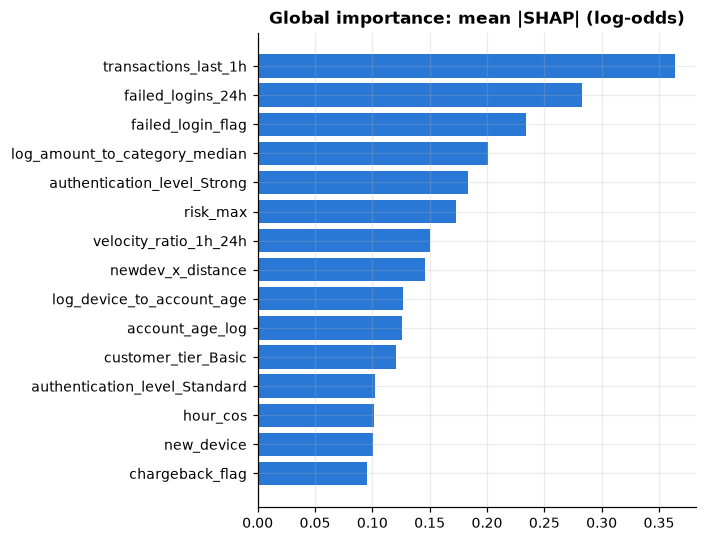

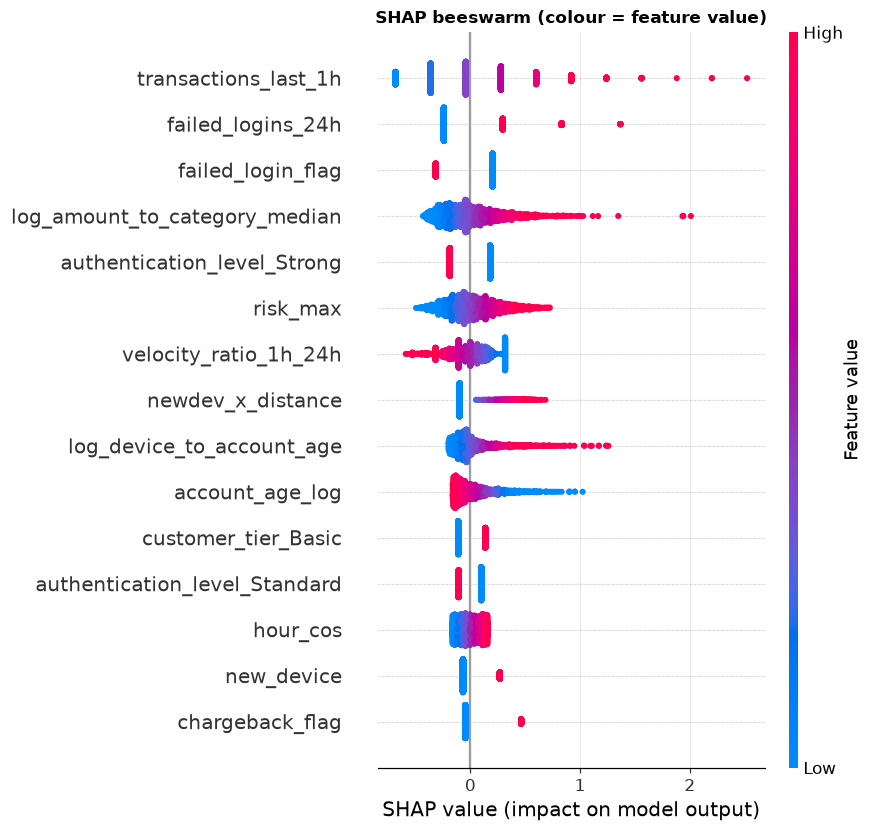

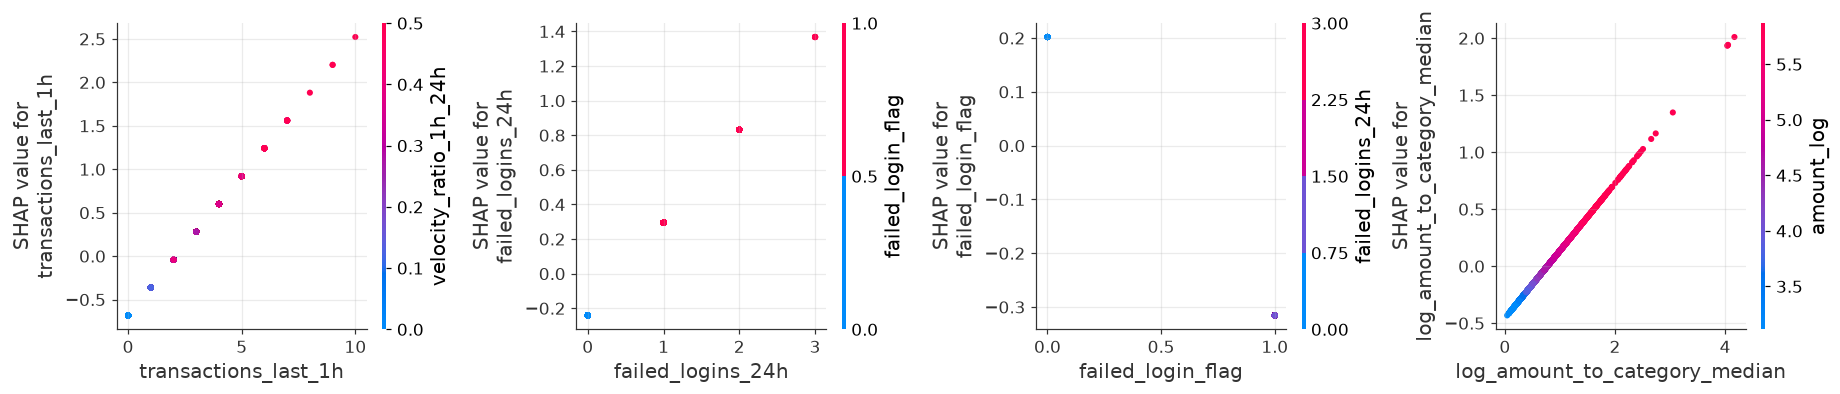

In [28]:
sv_d, Zd, base_val = explain.shap_values(base_pipe, Xd, background=Xd)
gi = explain.global_importance(sv_d, Zd, 20)
display(gi.to_frame("mean |SHAP|"))

R["shap_global"] = gi
gp = explain.plot_global(sv_d, Zd)
[show(p) for p in gp]

Zd_disp = explain.display_frame(base_pipe, Zd)
top4 = list(gi.index[:4])
dp = explain.plot_dependence(sv_d, Zd_disp, top4)
show(dp)

In [29]:
dirchk = explain.direction_check(sv_d, Zd, Xd, yd)
display(dirchk.head(15).round(3))

R["direction_check"] = dirchk
print("Features whose model direction disagrees with the raw fraud association:",
      list(dirchk[dirchk.direction_conflict].feature))

,feature,spearman_value_vs_shap,spearman_value_vs_fraud,mean_abs_shap,direction_conflict
4,transactions_last_1h,1.0000,0.0950,0.3640,False
7,failed_logins_24h,1.0000,0.0260,0.2830,False
43,failed_login_flag,-1.0000,0.0200,0.2340,False
19,log_amount_to_category_median,1.0000,0.0390,0.2010,False
78,authentication_level_Strong,-1.0000,-0.0350,0.1830,False
23,risk_max,1.0000,0.0990,0.1730,False
16,velocity_ratio_1h_24h,-1.0000,0.0810,0.1500,True
26,newdev_x_distance,1.0000,0.1060,0.1460,False
40,log_device_to_account_age,1.0000,0.0420,0.1260,False
38,account_age_log,-1.0000,-0.0480,0.1260,False


Features whose model direction disagrees with the raw fraud association: ['velocity_ratio_1h_24h', 'amount_z_tier', 'amount_log', 'device_older_than_account', 'n_missing', 'new_account_flag', 'transactions_last_24h', 'account_age_days', 'transaction_amount', 'risk_mean', 'log_email_to_account_age', 'merchant_risk_score', 'burst_flag']


In [30]:
# Stability of importance across the 5 CV folds (refit per fold, SHAP on that fold's validation rows)
stab, stab_raw, rank_corr = explain.fold_stability(
    clone(tuned[FINAL]["estimator"]), Xd, yd)

display(stab.head(15).round(3))
print("mean pairwise Spearman of fold importance vectors:", round(rank_corr, 3))

R["shap_stability"] = stab
R["shap_rank_corr"] = rank_corr

,mean_abs_shap,cv_of_importance,mean_rank,rank_std,in_top10_folds
transactions_last_1h,0.3380,0.1560,1.2000,0.4470,5
failed_logins_24h,0.2510,0.2530,2.6000,1.5170,5
failed_login_flag,0.2000,0.3210,5.2000,2.0490,5
authentication_level_Strong,0.1710,0.1420,5.2000,1.0950,5
risk_max,0.1670,0.4030,8.2000,6.9430,3
velocity_ratio_1h_24h,0.1350,0.1290,9.0000,1.0000,5
newdev_x_distance,0.1370,0.2320,9.8000,5.3570,4
log_amount_to_category_median,0.1560,0.5180,10.4000,8.8490,2
log_device_to_account_age,0.1300,0.3110,12.0000,9.1650,3
customer_tier_Basic,0.1150,0.1430,12.2000,3.5640,2


mean pairwise Spearman of fold importance vectors: 0.62


In [31]:
# Interaction analysis: needs a tree model (a linear model has none by construction). Use the best nonlinear model refit on dev.
tree_pipe = clone(tuned[best_tree]["estimator"]).fit(Xd, yd)
if best_tree == "rf":   # TreeExplainer interactions on a 400-tree forest are slow; use the boosted model for this analysis only
    alt = "lgbm" if tuned["lgbm"]["cv_pr_auc"] >= tuned["hgb"]["cv_pr_auc"] else "hgb"
    tree_pipe = clone(tuned["lgbm"]["estimator"]).fit(Xd, yd)

ints = explain.interaction_strengths(tree_pipe, Xd, n=500, top=10)
display(ints.round(4))

R["shap_interactions"] = ints
R["interaction_model"] = type(tree_pipe.steps[-1][1]).__name__

,feature_a,feature_b,mean_abs_interaction
0,merchant_risk_score,risk_max,0.1073
1,risk_mean,amount_x_merchant_risk,0.0644
2,distance_from_usual_location_km,device_age_days,0.0616
3,velocity_ratio_1h_24h,amount_x_merchant_risk,0.0554
4,merchant_risk_score,amount_x_merchant_risk,0.0523
5,device_age_days,log_device_to_account_age,0.0506
6,transaction_amount,log_amount_to_category_median,0.0502
7,login_to_transaction_minutes,log_email_to_account_age,0.0476
8,prior_chargebacks,risk_mean,0.0425
9,log_device_to_account_age,merchant_category_Jewelry,0.0415


,case,transaction_id,calibrated_prob,actual_fraud,reason_codes
0,Highest-risk transaction,TXN5002332,0.4154,0,"transactions_last_1h=5 (raises risk, +0.92); amount_extreme_flag=1 (raises risk, +0.81); log_amount_to_category_median=1.99 (raises risk, +0.72)"
1,Highest-score true fraud,TXN5002422,0.3635,1,"merchant_category_Jewelry=1 (raises risk, +0.45); newdev_x_distance=3.42 (raises risk, +0.41); transactions_last_1h=1 (lowers risk, -0.36)"
2,"Highest-score false positive (legitimate, blocked)",TXN5002576,0.3624,0,"transactions_last_1h=8 (raises risk, +1.88); amount_extreme_flag=1 (raises risk, +0.81); log_amount_to_category_median=1.78 (raises risk, +0.60)"
3,"Missed fraud (approved, lowest score)",TXN5002952,0.0599,1,"authentication_level_Missing=1 (raises risk, +0.55); transactions_last_1h=1 (lowers risk, -0.36); log_amount_to_category_median=0.171 (lowers risk, -0.36)"
4,Review borderline (closest to review threshold),TXN5001317,0.1793,0,"chargeback_flag=1 (raises risk, +0.46); merchant_category_Fashion=1 (raises risk, +0.28); transactions_last_1h=3 (raises risk, +0.28)"
5,Block borderline (closest to block threshold),TXN5001631,0.2387,0,"transactions_last_1h=4 (raises risk, +0.60); newdev_x_distance=3.8 (raises risk, +0.46); new_device=1 (raises risk, +0.27)"
6,Fraud with missing authentication,TXN5001403,0.3400,1,"authentication_level_Missing=1 (raises risk, +0.55); chargeback_flag=1 (raises risk, +0.46); merchant_category_Jewelry=1 (raises risk, +0.45)"
7,Reviewed legitimate (false alarm in review band),TXN5002156,0.3562,0,"transactions_last_1h=6 (raises risk, +1.24); newdev_x_distance=2.96 (raises risk, +0.34); failed_login_flag=1 (lowers risk, -0.32)"


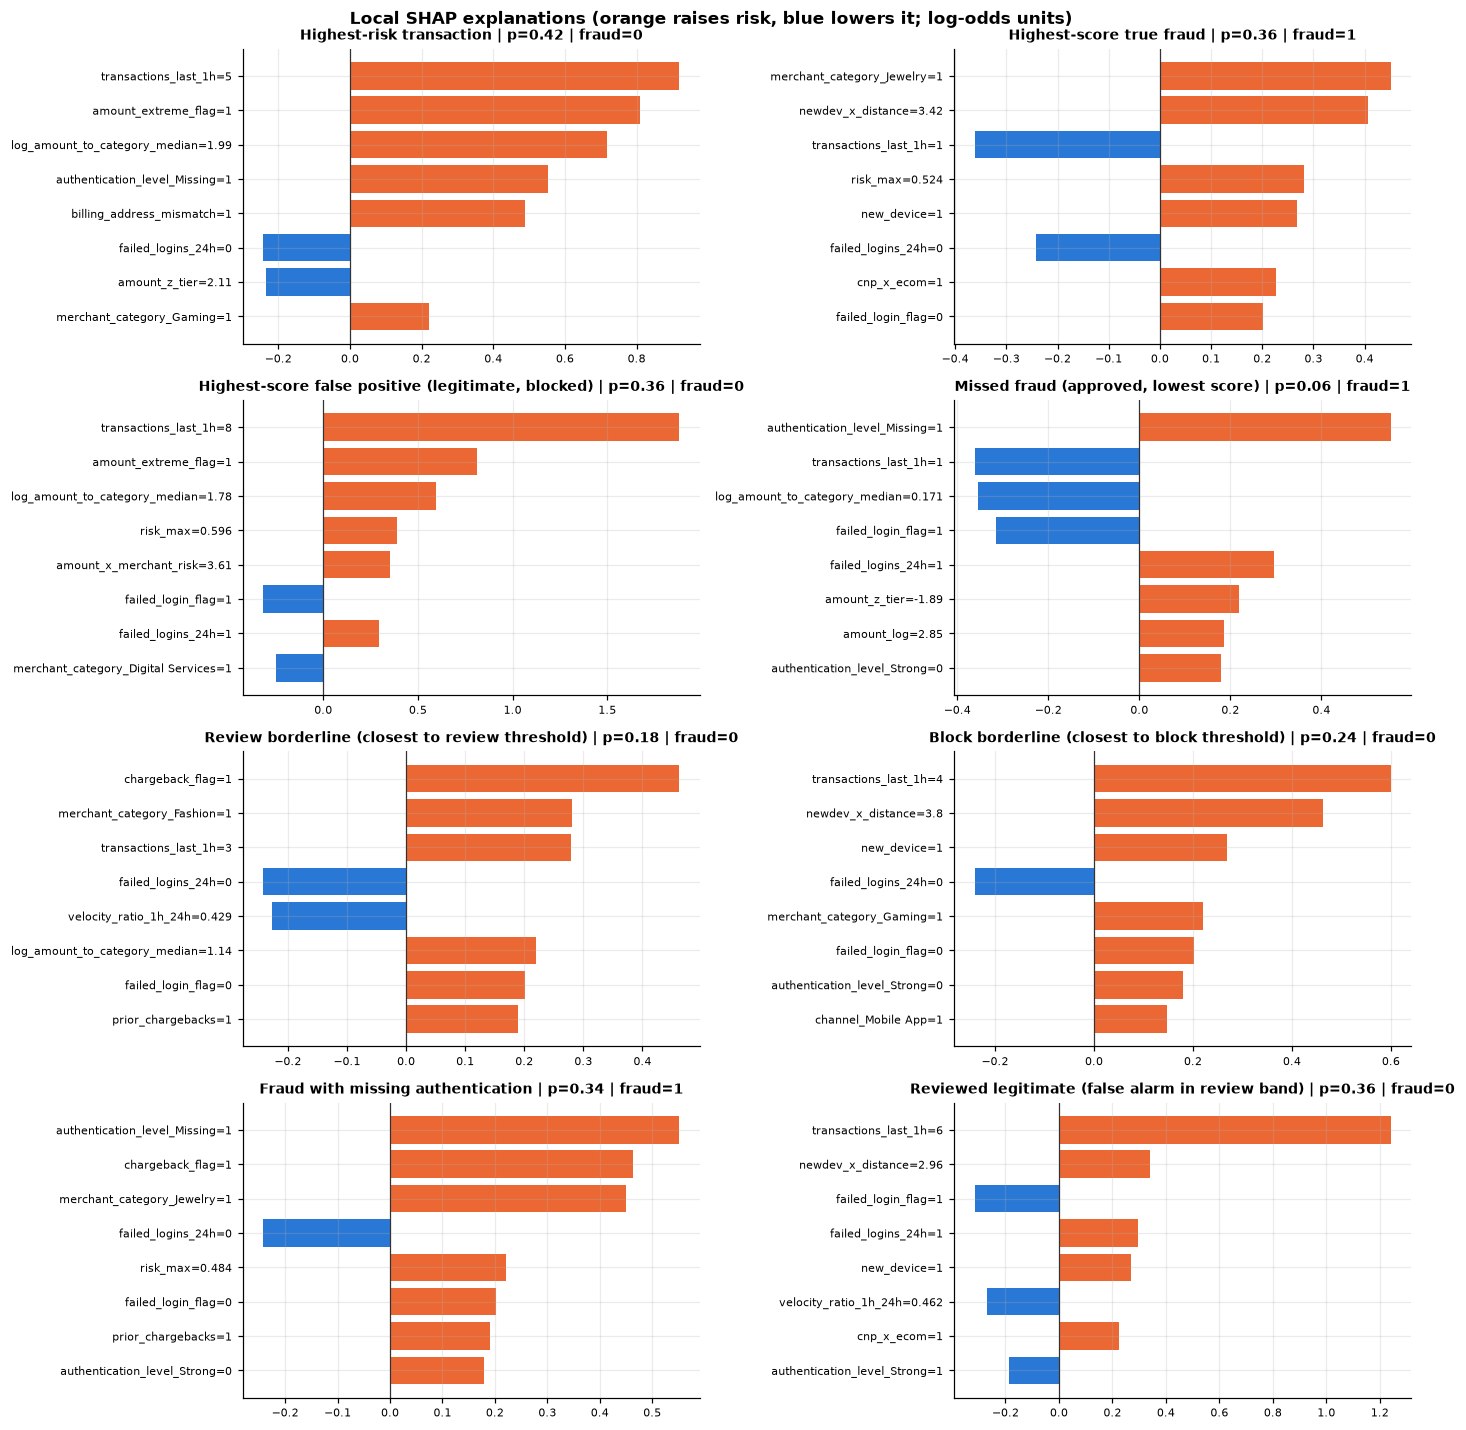

In [32]:
# Transaction-level explanations on the TEST set (8 cases) + reason codes
sv_t, Zt, _ = explain.shap_values(base_pipe, Xt, background=Xd)
Zt_disp = explain.display_frame(base_pipe, Zt)
ids = test.transaction_id.values
order = np.argsort(-p_t)
fn_pool = np.where((yt == 1) & (p_t < T_REV))[0]
fp_pool = np.where((yt == 0) & (p_t >= T_BLK))[0]
am_pool = np.where((yt == 1) & (Xt.authentication_level.isna().values))[0]
tp_pool = np.where(yt == 1)[0]
used = set()

def pick(pool, key, label, largest=True):
    pool = [i for i in pool if i not in used]
    if len(pool) == 0:
        return None
    i = int(max(pool, key=lambda j: key[j]) if largest else min(
        pool, key=lambda j: key[j]))
    used.add(i)
    return (label, i)

sel = [pick(range(len(yt)), p_t, "Highest-risk transaction"), pick(tp_pool, p_t, "Highest-score true fraud"),
       pick(fp_pool, p_t, "Highest-score false positive (legitimate, blocked)"), pick(
           fn_pool, p_t, "Missed fraud (approved, lowest score)", largest=False),
       pick(range(len(yt)), -np.abs(p_t - T_REV),
            "Review borderline (closest to review threshold)"),
       pick(range(len(yt)), -np.abs(p_t - T_BLK),
            "Block borderline (closest to block threshold)"),
       pick(am_pool, p_t, "Fraud with missing authentication"), pick(np.where((yt == 0) & (p_t >= T_REV))[0], p_t, "Reviewed legitimate (false alarm in review band)")]

sel = [x for x in sel if x is not None]
idxs = [int(i) for _, i in sel]
labs = [f"{l} | p={p_t[i]:.2f} | fraud={yt[i]}" for l, i in sel]
loc = explain.explain_transactions(sv_t, Zt_disp, ids, p_t, yt, idxs, [
                                   l for l, _ in sel], base_val)
pd.set_option("display.max_colwidth", 250)

display(loc)
R["local_explanations"] = loc
loc.to_csv(SUPP / "transaction_explanations.csv", index=False)
show(explain.plot_waterfalls(sv_t, Zt_disp, idxs, labs, base_val))

In [33]:
# Prove the engine end-to-end: calibrated probability + decision + reason codes for the first 6 test transactions flagged as non-Approve
eng = engine.FraudDecisionEngine(
    cal_model, base_pipe, policy, background=Xd.sample(200, random_state=SEED))
demo = eng.decide(Xt)
demo.insert(0, "transaction_id", ids)
demo["actual_fraud"] = yt

print(demo.decision.value_counts().to_dict())
display(demo[demo.decision != "Approve"].sort_values(
    "fraud_probability", ascending=False).head(6))

R["engine_demo"] = demo[demo.decision != "Approve"].sort_values(
    "fraud_probability", ascending=False).head(6)

{'Approve': 507, 'Review': 62, 'Block': 31}


,transaction_id,fraud_probability,decision,explanation,actual_fraud
430,TXN5002332,0.4154,Block,"transactions_last_1h=5 (raises risk, +0.95); amount_extreme_flag=1 (raises risk, +0.82); log_amount_to_category_median=1.99 (raises risk, +0.75)",0
439,TXN5002422,0.3635,Block,"merchant_category_Jewelry=1 (raises risk, +0.45); newdev_x_distance=3.42 (raises risk, +0.42); transactions_last_1h=1 (lowers risk, -0.34)",1
222,TXN5002576,0.3624,Block,"transactions_last_1h=8 (raises risk, +1.91); amount_extreme_flag=1 (raises risk, +0.82); log_amount_to_category_median=1.78 (raises risk, +0.63)",0
369,TXN5002156,0.3562,Block,"transactions_last_1h=6 (raises risk, +1.27); failed_logins_24h=1 (raises risk, +0.40); failed_login_flag=1 (lowers risk, -0.40)",0
55,TXN5002509,0.3500,Block,"log_amount_to_category_median=2.66 (raises risk, +1.15); failed_logins_24h=2 (raises risk, +0.94); amount_extreme_flag=1 (raises risk, +0.82)",1
412,TXN5000587,0.3453,Block,"transactions_last_1h=5 (raises risk, +0.95); log_device_to_account_age=2.59 (raises risk, +0.44); risk_product=0.323 (raises risk, +0.37)",1


## Robustness and stress testing
The **fixed** calibrated model and thresholds are applied to shifted copies of the test set. Shifts are applied to the *raw* fields, so the engineered features recompute exactly as they would in production. `cost_per_1000_txn` uses the base cost scenario and fixed thresholds (no re-optimisation), so it shows how the *deployed* policy degrades.

In [34]:
stress = robustness.stress_suite(
    cal_model, Xt, yt, AMT_FILL, T_REV, T_BLK, BASE)

display(stress.round(4))
R["stress"] = stress
stress.to_csv(SUPP / "stress_test_results.csv", index=False)

,scenario,n,fraud_rate,roc_auc,pr_auc,brier,mean_score,review_rate,block_rate,fraud_capture,cost_per_1000_txn
0,Baseline (test),600,0.1217,0.7119,0.2394,0.1013,0.1201,0.1033,0.0517,0.3178,13029.4167
1,Amounts x1.5,600,0.1217,0.7137,0.2351,0.1012,0.1267,0.0967,0.0833,0.3479,17006.2467
2,Amounts x2,600,0.1217,0.7031,0.2180,0.1023,0.1341,0.1183,0.0983,0.4000,19766.5133
3,Velocity +1 (1h) / +3 (24h),600,0.1217,0.7129,0.2357,0.1014,0.1372,0.1283,0.0917,0.4151,12351.5900
4,Merchant & IP risk +0.10,600,0.1217,0.7092,0.2347,0.1016,0.1431,0.1383,0.1017,0.4425,11903.2600
5,E-commerce share 45%,600,0.1333,0.6771,0.2224,0.1120,0.1225,0.1233,0.0583,0.3212,14484.9933
6,E-commerce share 10%,600,0.1067,0.7343,0.2437,0.0899,0.1153,0.0883,0.0550,0.3094,11516.7617
7,Extra missing values 5%,600,0.1217,0.7160,0.2454,0.1012,0.1159,0.0917,0.0483,0.2808,13553.7050
8,Extra missing values 10%,600,0.1217,0.7066,0.2367,0.1016,0.1116,0.0817,0.0450,0.2438,13890.1917
9,Extra missing values 20%,600,0.1217,0.7198,0.2537,0.1012,0.1029,0.0583,0.0317,0.1932,15383.7517


In [35]:
# Fold-to-fold variability of the final model (5x3 repeated CV, per-fold metrics)
fk = [k for k in folds if k.startswith(models.MODEL_LABELS[FINAL])][0]
ff = folds[fk]
var = pd.DataFrame({"mean": ff[["roc_auc", "pr_auc", "brier", "recall", "precision"]].mean(), "std": ff[["roc_auc", "pr_auc", "brier", "recall", "precision"]].std(),
                    "min": ff[["roc_auc", "pr_auc", "brier", "recall", "precision"]].min(), "max": ff[["roc_auc", "pr_auc", "brier", "recall", "precision"]].max()})
var["cv_%"] = 100 * var["std"] / var["mean"]

display(var.round(4))
R["fold_variability"] = var

# bootstrap CI of the test metrics
bs = []
for _ in range(1000):
    i = rng.integers(0, len(yt), len(yt))
    if yt[i].sum() == 0:
        continue
    bs.append((roc_auc_score(yt[i], p_t[i]),
              average_precision_score(yt[i], p_t[i])))

bs = np.array(bs)
R["test_ci"] = {"roc_auc": np.percentile(
    bs[:, 0], [2.5, 97.5]), "pr_auc": np.percentile(bs[:, 1], [2.5, 97.5])}

print(R["test_ci"])

,mean,std,min,max,cv_%
roc_auc,0.6707,0.0453,0.5898,0.7411,6.7597
pr_auc,0.2493,0.0432,0.1798,0.3262,17.3155
brier,0.1046,0.0066,0.0962,0.1238,6.3413
recall,0.0561,0.0221,0.0172,0.1034,39.3198
precision,0.4107,0.1797,0.1429,0.8000,43.7567


{'roc_auc': array([0.65106711, 0.77268726]), 'pr_auc': array([0.18028668, 0.3372738 ])}


## Model governance inputs: drift and monitoring
PSI (population stability index) on the raw inputs and on the model score, dev vs test (both drawn from the same random split, so these values show the **noise floor**), plus PSI under two simulated shifts to show the detector fires. Conventional reading: <0.10 stable, 0.10-0.25 watch, >0.25 act.

In [36]:
cols = [c for c in Xd.columns if c != "transaction_id"]
psi_noise = robustness.psi_table(Xd, Xt, cols).rename(
    columns={"psi": "psi_dev_vs_test"})
Xs1 = robustness.shift_amount(Xt, 1.5)
Xs2, _ = robustness.shift_channel_mix(Xt, yt, 0.10)
Xs3 = robustness.shift_risk(robustness.shift_velocity(Xt), 0.10)

for lab, Xs in [("psi_amount_x1.5", Xs1), ("psi_ecom_share_10pct", Xs2), ("psi_velocity_risk_shift", Xs3)]:
    psi_noise = psi_noise.merge(robustness.psi_table(
        Xd, Xs, cols).rename(columns={"psi": lab}), on="feature")
score_psi = {"dev_vs_test": robustness.psi(cal_model.predict_proba(Xd)[:, 1], p_t), "amount_x1.5": robustness.psi(cal_model.predict_proba(Xd)[:, 1], cal_model.predict_proba(Xs1)[:, 1]),
             "ecom_share_10pct": robustness.psi(cal_model.predict_proba(Xd)[:, 1], cal_model.predict_proba(Xs2)[:, 1]), "velocity_risk_shift": robustness.psi(cal_model.predict_proba(Xd)[:, 1], cal_model.predict_proba(Xs3)[:, 1])}

display(psi_noise.head(14).round(3))
print("score PSI:", {k: round(v, 3) for k, v in score_psi.items()})

R["psi"] = psi_noise
R["score_psi"] = score_psi
psi_noise.to_csv(SUPP / "psi_demonstration.csv", index=False)

,feature,psi_dev_vs_test,psi_amount_x1.5,psi_ecom_share_10pct,psi_velocity_risk_shift
0,login_to_transaction_minutes,0.0520,0.0520,0.0550,0.0520
1,merchant_category,0.0250,0.0250,0.0510,0.0250
2,hour,0.0240,0.0240,0.0370,0.0240
3,account_age_days,0.0240,0.0240,0.0610,0.0240
4,ip_risk_score,0.0190,0.0190,0.1070,1.6460
5,transactions_last_24h,0.0170,0.0170,0.0180,1.0870
6,merchant_risk_score,0.0160,0.0160,0.0430,0.6130
7,email_age_days,0.0160,0.0160,0.0650,0.0160
8,customer_tier,0.0160,0.0160,0.0210,0.0160
9,day_of_week,0.0140,0.0140,0.0180,0.0140


score PSI: {'dev_vs_test': 0.016, 'amount_x1.5': 0.023, 'ecom_share_10pct': 0.055, 'velocity_risk_shift': 0.456}


## Governance: monitoring metrics and lifecycle triggers
Ten production monitoring metrics with warn/act thresholds (derived from the fold variability and PSI results above) and explicit retrain / review / disable rules. The full model card is `06_model_card.pdf`.

In [37]:
from fraud_engine import reporting

mon = reporting.monitoring_table(R)
display(mon)
mon.to_csv(SUPP / "monitoring_plan.csv", index=False)

R["monitoring"] = mon
for a, t in reporting.ACTIONS:
    print(f"{a.upper()}: {t}\n")

,Metric,Baseline (this evaluation),Thresholds,Frequency
0,"Rolling PR-AUC (labelled, 30-day cohorts)",0.25 (CV mean),Warn below 0.19; act below 0.16 (mean - 2 sd),"Weekly, once chargebacks mature"
1,Rolling ROC-AUC,0.67,Warn below 0.61; act below 0.58,Weekly
2,"Calibration: slope, ECE, mean predicted vs observed rate",slope about 1.0; mean predicted 12.1% vs observed 12.1%,Warn slope outside 0.8-1.2 or |mean gap| > 1.5 pts; act outside 0.6-1.4 or gap > 3 pts,Weekly
3,Score PSI (calibrated probability),below 0.02 (dev vs test),Warn 0.10; act 0.25,Daily
4,Feature PSI for the 10 most important inputs,below 0.06,Warn 0.10; act 0.25 on any top-5 feature,Daily
5,Review rate and block rate,10.3% / 5.2% of volume,Warn review > 12% or block > 6%; act review > 15% (capacity breach),Daily
6,Fraud capture and false-positive burden (confirmed labels),capture 32% of fraud cases (test),Warn capture down 25% relative; act down 40%,Weekly
7,"Data quality: missing rate per field, share of authentication_level missing",numeric 1.5-2.5%; auth 9.6%,Warn if any field exceeds 2x baseline; act if > 4x,Daily
8,Label delay and label coverage,n/a (not in dataset),Warn if < 80% of cohort labelled at day 45,Weekly
9,"Expected vs realised cost per 1,000 transactions","base scenario $14,905 (dev OOF)",Warn if realised > expected by 15%; act by 30%,Monthly


RETRAIN: Scheduled quarterly, or earlier when: score PSI > 0.25 for 7 consecutive days; rolling PR-AUC falls below the act level for 2 consecutive weeks; calibration slope leaves 0.6-1.4; a top-5 feature definition changes. Recalibrate only (keep the model, refit Platt scaling) when ranking metrics are healthy but calibration drifts.

REVIEW (HUMAN MODEL-RISK REVIEW): Any change to data feeds feeding velocity counters, authentication_level, merchant or IP risk scores; any new channel or country; cost-assumption changes (e.g. staffing, chargeback fees); new fairness findings; the first 90 days after launch.

TEMPORARILY DISABLE (FALL BACK TO RULES + MANUAL PROCESS): Rolling ROC-AUC below the act level for 2 consecutive weeks AND a confirmed data fault; missing rate of velocity or authentication fields above 25%; review queue above 150% of capacity for more than 3 days; score PSI above 0.50; or an incident where the score distribution collapses (e.g. more than 90% of scores in one 0.01 b

## Deliverable files
`processed_dataset.csv` holds the engineered feature table for all 3,000 rows. The feature transformer is fitted on the **development rows only** and applied to the test rows. Missing values are left as NaN (imputation happens inside the model pipeline).

In [38]:
import os

fe_final = base_pipe.named_steps["fe"]
proc = fe_final.transform(df.drop(columns=[TARGET])).copy()
proc.insert(0, "transaction_id", df.transaction_id.values)
split_lab = pd.Series("train", index=df.index)
split_lab[df.transaction_id.isin(test.transaction_id)] = "test"
proc.insert(1, "split", split_lab.values)
proc[TARGET] = df[TARGET].values
proc.to_csv(OUT / "processed_dataset.csv", index=False)

print(proc.shape, proc.split.value_counts().to_dict())
joblib.dump(R, SUPP / "results.joblib")
print(sorted(os.listdir(OUT)))

(3000, 58) {'train': 2400, 'test': 600}
['03_fraud_model_pipeline.joblib', '04_calibrated_model.joblib', '05_threshold_cost_analysis.csv', 'cache', 'decision_policy.json', 'figures', 'processed_dataset.csv', 'supplementary']
